# Análise de Portfólio Amazon Índia: Preço, Engajamento e Satisfação

*Como preço e desconto se relacionam com o engajamento e a satisfação dos clientes*



**Tech Challenge · Fase 4 · Pós-graduação em Data Analytics · FIAP**

**Equipe (Grupo 158):** Marília Aparecida da Silva Lima, Fernando Rosa Salles, Guilherme Alfredo Palitos Alves

**Dados:** Amazon Sales Dataset, por Karkavelraja J. Kaggle.

*Disponível em: kaggle.com/datasets/karkavelraja/amazon-sales-dataset*

# **Limpeza**

In [213]:
# Bibliotecas inicial
import pandas as pd
import numpy as np
import re

In [214]:
# 1. CARREGAR A BASE ORIGINAL

df = pd.read_csv('../data/amazon.csv')
print(f" Base original: {len(df)} linhas")

 Base original: 1465 linhas


In [215]:
df

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,₹199,"₹1,899",90%,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,₹329,₹699,53%,4.2,"94,363",The boAt Deuce USB 300 2 in 1 cable is compati...,"AEWAZDZZJLQUYVOVGBEUKSLXHQ5A,AG5HTSFRRE6NL3M5S...","Omkar dhale,JD,HEMALATHA,Ajwadh a.,amar singh ...","R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,₹154,₹399,61%,4.2,"16,905",[CHARGE & SYNC FUNCTION]- This cable comes wit...,"AE3Q6KSUK5P75D5HFYHCRAOLODSA,AFUGIFH5ZAFXRDSZH...","rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK...","R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1460,B08L7J3T31,Noir Aqua - 5pcs PP Spun Filter + 1 Spanner | ...,Home&Kitchen|Kitchen&HomeAppliances|WaterPurif...,₹379,₹919,59%,4,"1,090",SUPREME QUALITY 90 GRAM 3 LAYER THIK PP SPUN F...,"AHITFY6AHALOFOHOZEOC6XBP4FEA,AFRABBODZJZQB6Z4U...","Prabha ds,Raghuram bk,Real Deal,Amazon Custome...","R3G3XFHPBFF0E8,R3C0BZCD32EIGW,R2EBVBCN9QPD9R,R...","Received the product without spanner,Excellent...","I received product without spanner,Excellent p...",https://m.media-amazon.com/images/I/41fDdRtjfx...,https://www.amazon.in/Noir-Aqua-Spanner-Purifi...
1461,B01M6453MB,Prestige Delight PRWO Electric Rice Cooker (1 ...,Home&Kitchen|Kitchen&HomeAppliances|SmallKitch...,"₹2,280","₹3,045",25%,4.1,"4,118","230 Volts, 400 watts, 1 Year","AFG5FM3NEMOL6BNFRV2NK5FNJCHQ,AGEINTRN6Z563RMLH...","Manu Bhai,Naveenpittu,Evatira Sangma,JAGANNADH...","R3DDL2UPKQ2CK9,R2SYYU1OATVIU5,R1VM993161IYRW,R...","ok,everything was good couldn't return bcoz I ...","ok,got everything as mentioned but the me

In [216]:
# 2. LIMPEZA DE CARACTERES ESTRANHOS

def limpar_texto(texto):
    """Remove caracteres de escape, aspas extras e sujeira de scraping"""
    if pd.isna(texto):
        return np.nan

    texto = str(texto)

    # Remove [' e '] (restos de lista Python)
    texto = texto.replace("['", "").replace("']", "")
    texto = texto.replace('["', '').replace('"]', '')

    # Remove caracteres de escape (\n, \t, \\, etc.)
    texto = texto.replace('\\n', ' ')
    texto = texto.replace('\\t', ' ')
    texto = texto.replace('\\\\', ' ')
    texto = texto.replace('\\"', '"')
    texto = texto.replace("\\'", "'")

    # Remove aspas extras no início e fim
    texto = texto.strip('"').strip("'")

    # Remove "!!" e outros caracteres especiais do início/fim
    texto = texto.strip('!').strip('-').strip('_').strip('*').strip('#')

    # Remove espaços extras
    texto = re.sub(r'\s+', ' ', texto).strip()

    # Se ficou vazio ou só com caracteres estranhos, retorna NaN
    if texto in ['', 'nan', 'None', 'null', "['']", '[]']:
        return np.nan

    return texto

# Aplica a limpeza nas colunas problemáticas (product_name)
colunas_para_limpar = ['user_id', 'user_name', 'review_id', 'review_title', 'review_content', 'about_product', 'product_name']

for col in colunas_para_limpar:
    if col in df.columns:
        df[col] = df[col].apply(limpar_texto)
        print(f" Coluna '{col}' limpa")

print("\n Limpeza de caracteres estranhos concluída!")

 Coluna 'user_id' limpa
 Coluna 'user_name' limpa
 Coluna 'review_id' limpa
 Coluna 'review_title' limpa
 Coluna 'review_content' limpa
 Coluna 'about_product' limpa
 Coluna 'product_name' limpa

 Limpeza de caracteres estranhos concluída!


In [217]:
# 3. LIMPEZA DAS COLUNAS NUMÉRICAS

def extrair_numero(valor):
    if pd.isna(valor): return np.nan
    return float(re.sub(r'[^\d.]', '', str(valor)))

df['actual_price'] = df['actual_price'].apply(extrair_numero)
df['discounted_price'] = df['discounted_price'].apply(extrair_numero)
df['discount_percentage'] = df['discount_percentage'].apply(extrair_numero)
df['rating'] = pd.to_numeric(df['rating'], errors='coerce')
df['rating_count'] = df['rating_count'].apply(extrair_numero).fillna(0).astype(int)

print("Colunas numéricas limpas")

Colunas numéricas limpas

In [218]:
# 4. DEDUPLICAÇÃO POR product_id

df_ordenado = df.sort_values(
    by=['rating_count', 'actual_price'],
    ascending=[False, True]
)

df_sem_dup_id = df_ordenado.drop_duplicates(subset=['product_id'], keep='first')
print(f"\n Após remover duplicatas por product_id:")
print(f"   De {len(df)} para {len(df_sem_dup_id)} linhas")

# 5. DEDUPLICAÇÃO POR product_name

df_sem_dup_id['nome_normalizado'] = df_sem_dup_id['product_name'].str.lower().str.strip()

df_sem_dup_id = df_sem_dup_id.sort_values(
    by=['nome_normalizado', 'rating_count'],
    ascending=[True, False]
)

df_limpo = df_sem_dup_id.drop_duplicates(subset=['nome_normalizado'], keep='first')
df_limpo = df_limpo.drop(columns=['nome_normalizado'])

print(f"\n Após remover duplicatas por product_name:")
print(f"   De {len(df_sem_dup_id)} para {len(df_limpo)} linhas")


 Após remover duplicatas por product_id:
   De 1465 para 1351 linhas

 Após remover duplicatas por product_name:
   De 1351 para 1337 linhas


In [219]:
# 6. CRIAR COLUNA Faixa_Nota

def criar_faixa_nota(rating):
    if pd.isna(rating):
        return np.nan
    elif rating >= 5.0:
        return 5
    elif rating >= 4.0:
        return 4
    elif rating >= 3.0:
        return 3
    elif rating >= 2.0:
        return 2
    else:
        return 1

df_limpo['Faixa_Nota'] = df_limpo['rating'].apply(criar_faixa_nota)
print(f"\nColuna 'Faixa_Nota' criada")


Coluna 'Faixa_Nota' criada


In [220]:
# 7. QUEBRAR A CATEGORIA

def extrair_categoria(texto, posicao):
    if pd.isna(texto):
        return np.nan
    partes = str(texto).split('|')
    if posicao < len(partes):
        return partes[posicao].strip()
    return np.nan

df_limpo['categoria_principal'] = df_limpo['category'].apply(lambda x: extrair_categoria(x, 0))
df_limpo['categoria_secundaria'] = df_limpo['category'].apply(lambda x: extrair_categoria(x, 1))

print(f"\n Colunas de categoria criadas:")
print(f"   Categorias principais únicas: {df_limpo['categoria_principal'].nunique()}")
print(f"   Categorias secundárias únicas: {df_limpo['categoria_secundaria'].nunique()}")


 Colunas de categoria criadas:
   Categorias principais únicas: 9
   Categorias secundárias únicas: 29


In [221]:
# 9. PREPARAR ARQUIVO 2: TABELA FATO

def explode_alinhado(row, cols_to_explode):
    """
    Faz explode alinhado: cada elemento da lista fica na sua linha correspondente
    """
    first_col = cols_to_explode[0]
    list_length = len(row[first_col]) if isinstance(row[first_col], list) else 1

    rows = []
    for i in range(list_length):
        new_row = {}
        for col in df_limpo.columns:
            if col in cols_to_explode:
                if isinstance(row[col], list) and i < len(row[col]):
                    new_row[col] = row[col][i]
                else:
                    new_row[col] = np.nan
            else:
                new_row[col] = row[col]
        rows.append(new_row)

    return pd.DataFrame(rows)

In [222]:
# Função para limpar colchetes e aspas (novamente)

def limpar_colchetes(texto):
    """Remove colchetes e aspas de IDs"""
    if pd.isna(texto):
        return np.nan

    texto = str(texto)

    # Remove colchetes
    texto = texto.replace('[', '').replace(']', '')

    # Remove aspas simples e duplas
    texto = texto.replace("'", '').replace('"', '')

    # Remove espaços extras
    texto = texto.strip()

    if texto in ['', 'nan', 'None']:
        return np.nan

    return texto

# ============================================

# Separa as colunas de ID por vírgula

cols_ids = ['user_id', 'user_name', 'review_id']
for col in cols_ids:
    df_limpo[col] = df_limpo[col].astype(str).str.split(',')

# ============================================

# Aplica a limpeza de colchetes em cada elemento das listas

for col in cols_ids:
    df_limpo[col] = df_limpo[col].apply(
        lambda lista: [limpar_colchetes(item) for item in lista] if isinstance(lista, list) else limpar_colchetes(lista)
    )
    print(f" Coluna '{col}' limpa de colchetes e aspas")

# ============================================

# Aplica o explode alinhado

df_fato_list = []
for idx, row in df_limpo.iterrows():
    exploded = explode_alinhado(row, cols_ids)
    df_fato_list.append(exploded)

df_fato = pd.concat(df_fato_list, ignore_index=True)

# Seleciona apenas as colunas necessárias
cols_fato = ['product_id', 'user_id', 'user_name', 'review_id', 'rating_count']
df_fato = df_fato[cols_fato]

# Remove IDs inválidos
df_fato = df_fato[df_fato['user_id'].notna()]
df_fato = df_fato[df_fato['review_id'].notna()]
df_fato = df_fato[df_fato['user_id'] != 'nan']
df_fato = df_fato[df_fato['review_id'] != '']

df_limpo.to_csv('../output/01_Tabela_Produtos.csv', index=False, encoding='utf-8-sig', decimal=',')
print(f"\n Arquivo 1 salvo: '01_Tabela_Produtos.csv'")

df_fato.to_csv('../output/02_Tabela_Fato_Reviews.csv', index=False, encoding='utf-8-sig', decimal=',')
print(f"\n Arquivo 2 salvo: '02_Tabela_Fato_Reviews.csv'")
print(f"   Total de reviews: {len(df_fato)}")

# Verificação
exemplo = df_fato[df_fato['product_id'] == 'B0BMTZ4T1D'][['product_id', 'user_name', 'review_id']].head()
print(f"\n Exemplo de alinhamento correto:")
print(exemplo)

 Coluna 'user_id' limpa de colchetes e aspas
 Coluna 'user_name' limpa de colchetes e aspas
 Coluna 'review_id' limpa de colchetes e aspas

 Arquivo 1 salvo: '01_Tabela_Produtos.csv'

 Arquivo 2 salvo: '02_Tabela_Fato_Reviews.csv'
   Total de reviews: 10496

 Exemplo de alinhamento correto:
   product_id    user_name       review_id
0  B0BMTZ4T1D   Neha Gupta  R2SBOJRVH87Z3A
1  B0BMTZ4T1D        Abhay  R2JZAP6U9T86EI
2  B0BMTZ4T1D  sumit kumar  R2FUR9B0B9PHCM
3  B0BMTZ4T1D       Kundan  R31RUINAE4JQ9V
4  B0BMTZ4T1D     Bond 007  R1L8EBC22RKCG5


In [223]:
# RESUMO FINAL

print("\n" + "="*60)
print("LIMPEZA COMPLETA CONCLUÍDA!")
print("="*60)
print(f"Base original: {len(df)} linhas")
print(f"Produtos únicos: {len(df_limpo)}")
print(f"Reviews explodidos: {len(df_fato)}")
print(f"Colunas limpas: user_id, user_name, review_id, about_product")
print("="*60)


LIMPEZA COMPLETA CONCLUÍDA!
Base original: 1465 linhas
Produtos únicos: 1337
Reviews explodidos: 10496
Colunas limpas: user_id, user_name, review_id, about_product


In [224]:
df_limpo

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link,Faixa_Nota,categoria_principal,categoria_secundaria
1158,B0BMTZ4T1D,1000 Watt/2000-Watt Room Heater!! Fan Heater!!...,"Home&Kitchen|Heating,Cooling&AirQuality|RoomHe...",784.0,1599.0,51.0,4.5,11,2000 Watt Fan heater with dual heat setting|Ca...,"[AFEKJVIJNA64W3J3MTGDJUQ6TQOA, AFAILC2MZIU2UFL...","[Neha Gupta, Abhay, sumit kumar, Kundan, Bond ...","[R2SBOJRVH87Z3A, R2JZAP6U9T86EI, R2FUR9B0B9PHC...","👍,Good quality product and value for money. Re...","Very good,Good quality product and value for m...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/2000-Watt-Heater-White-H...,4.0,Home&Kitchen,"Heating,Cooling&AirQuality"
137,B08TGG316Z,"10k 8k 4k HDMI Cable, Certified 48Gbps 1ms Ult...","Electronics|HomeTheater,TV&Video|Accessories|C...",999.0,2399.0,58.0,4.6,3664,Certified HDMI Cable: The package has an offic...,"[AFO7T5DJCA34LXNLPEMNTUPHBA3Q, AEOKQXQO42VI27R...","[Mandar Joglekar, Vasanth, Well person]","[R1482M3Z6TF62M, RX9ISCNT5KUMA, RY1MX82BJD2VD]","Fantastic Ultra High Speed HDMI cable,Amazing ...",Absolutely value for money. I connect it with ...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Cable-Certified-48Gbps-U...,4.0,Electronics,"HomeTheater,TV&Video"
549,B09RFB2SJQ,10WeRun Id-116 Bluetooth Smartwatch Wireless F...,Electronics|WearableTechnology|SmartWatches,499.0,1899.0,74.0,4.1,412,"All-day activity tracking: Track steps, distan...","[AHR4WZ6M4WXGQP65Z6SSP4LBJJ7A, AFWCLXKTHZPXBGF...","[Richard, Venkatesan, shakeel ahmad, Mohd Kaif...","[R31BGTIUFLQNT5, R1OQRF5LZIEHR4, R29Q5SDNP9JWZ...","It's worth for money and satisfied.,Nice produ...",It's good product and value for money. it's co...,https://m.media-amazon.com/images/I/41YwW+O-SK...,https://www.amazon.in/10WERUN-Bluetooth-Smartw...,4.0,Electronics,WearableTechnology
825,B00N1U7JXM,"3M Post-it Sticky Note Cube, 200 Sheets (4 Col...",OfficeProducts|OfficePaperProducts|Paper|Stati...,90.0,175.0,49.0,4.4,7429,"Material: Paper; Size: 3""x3""|Colour:Multicolou...","[AFCNMPYF3HBJZ3FYMKXQAMR55OSA, AFW6KM45ORMBEVY...","[Deepak kumar, Ahsan Shaikh, Karan Khanna, Sag...","[R3JRQ21J8LHK67, R2100TLJUT7YQM, R12XEPS4NQ1XI...","Adhesion,Good product,Does not stick,Nice stic...",It's a good product but the paper sometimes do...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Post-Cubes-sheets-colour...,4.0,OfficeProducts,OfficePaperProducts
617,B00N1U9AJS,3M Scotch Double Sided Heavy Duty Tape(1m hold...,Home&Kitchen|CraftMaterials|Scrapbooking|Tape,130.0,165.0,21.0,3.9,14778,"Sticks to most surfaces includingwalls, cerami...","[AGXGYUPGIFDGD6LPTVB2XVE7JWNA, AH2ZUPRKPAFHMLF...","[Amit Shrivastava, Sikandar kunar, INSTALL INT...","[R2U4L5Y1EI2L9P, R17YBU9W32A30N, R29OI40B53G6U...","Good Quality adhesive, easy to use,Good,good p...",Quality of adhesive is very good. I used it to...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Scotch-Double-Foam-Tape-...,3.0,Home&Kitchen,CraftMaterials
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32,B08QSC1XY8,Zoul USB C 60W Fast Charging 3A 6ft/2M Long Ty...,Computers&Accessories|Accessories&Peripherals|...,389.0,1099.0,65.0,4.3,974,{3A/QC 3.0 FAST CHARGING and DATA SYNC} : This...,"[AHMKXORT3VNMB75C3EUBYMFYELFQ, AEKJRELVNMICYPO...","[Pratyush Pahuja, Thiyagarajan, yeses, Amazon ...","[R2S0AYWUV349HP, R35OW9CYQNAYHY, R3B3DDF1D5NUL...","Great Cable, Charging Speeds Could Be Better,G...",Not charging as fast as I'd have expected. May...,https://m.media-amazon.com/images/I/419QKVTxaS...,https://www.amazon.in/Charging-Braided-Charger...,4.0,Computers&Accessories,Accessories&Peripherals
177,B08PSVBB2X,Zoul USB C to USB C Fast Charging Cable 65W Ty...,Computers&Accessories|Accessories&Peripherals|...,399.0,1099.0,64.0,4.1,2685,

In [225]:
df_fato

,product_id,user_id,user_name,review_id,rating_count
0,B0BMTZ4T1D,AFEKJVIJNA64W3J3MTGDJUQ6TQOA,Neha Gupta,R2SBOJRVH87Z3A,11
1,B0BMTZ4T1D,AFAILC2MZIU2UFLQK34GQLE4Q42A,Abhay,R2JZAP6U9T86EI,11
2,B0BMTZ4T1D,AGYG6IP3252GADX6BGGRZFNJGN2Q,sumit kumar,R2FUR9B0B9PHCM,11
3,B0BMTZ4T1D,AGVR6CP2GL562CMMN3TJJDIBQKOA,Kundan,R31RUINAE4JQ9V,11
4,B0BMTZ4T1D,AGRSBPMGH7TCQPCZ7XD7GLEJ7NBQ,Bond 007,R1L8EBC22RKCG5,11
...,...,...,...,...,...
10491,B0BLC2BYPX,AHDOOBJBPVJQCWTNVD4L5VIQBBWA,Kush,R3IEB79VMJ4KUB,54
10492,B0BLC2BYPX,AGXWSSAGJWT437I6SEHW2DBHPAUQ,Vani Prabha,R2FW55EB4WH4HM,54
10493,B0BLC2BYPX,AHP75RDBGYFPLYD5NVTHZMNJUOAQ,neha,RKHYI4QXIDG0B,54
10494,B0BLC2BYPX,AFBWWOUHEYFHDWJOE42DN5YWO2MQ,Reena Chahar,RR30YFP5QKZZZ,54


# **Analisando sentimentos**


In [226]:
# Biblioteca para analisar os sentimentos

import nltk
import re
nltk.download('vader_lexicon')
from nltk.sentiment import SentimentIntensityAnalyzer

from langdetect import detect, DetectorFactory
from deep_translator import GoogleTranslator

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\danie\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


In [227]:
sia = SentimentIntensityAnalyzer()

df = pd.read_csv('../output/01_Tabela_Produtos.csv')  # seu arquivo tratado
df = df[['product_id', 'review_id', 'review_title', 'review_content']]

# variações do mesmo produto têm a mesma lista de reviews: fica 1 linha por grupo
df = df.drop_duplicates(subset='review_id')

df['texto'] = (df['review_title'].fillna('') + ' ' + df['review_content'].fillna('')).str.lower()

# 1. Sentimento dos comentários de cada produto
df['score'] = df['texto'].apply(lambda t: sia.polarity_scores(t)['compound'])
df['sentimento'] = pd.cut(df['score'], bins=[-1.01, -0.05, 0.5, 1.01],
                          labels=['Negativo', 'Misto', 'Positivo'])

print(df['sentimento'].value_counts(normalize=True))  # confere a distribuição

# Função para calcular o percentual de frases negativas antes de exportar
def calcular_pct_frases_negativas(t):
    frases = [f for f in re.split(r'[.!?]', t) if len(f.strip()) > 3]
    if not frases:
        return 0.0
    neg = sum(sia.polarity_scores(f)['compound'] < -0.05 for f in frases)
    return neg / len(frases)

df['pct_frases_negativas'] = df['texto'].apply(calcular_pct_frases_negativas)


sentimento
Positivo    0.932546
Negativo    0.037099
Misto       0.030354
Name: proportion, dtype: float64


In [228]:
# 2. Temas citados nos comentários
temas = {
    'Qualidade': ['quality', 'build', 'material'],
    'Custo-benefício': ['value for money', 'worth', 'price'],
    'Bateria/Carga': ['battery', 'charging', 'charge'],
    'Som': ['sound', 'bass', 'audio'],
    'Durabilidade': ['durable', 'stopped working', 'broke', 'lasted'],
    'Defeito': ['not working', 'defective', 'damaged', 'faulty'],
    'Entrega/Embalagem': ['delivery', 'packaging', 'package'],
    'Facilidade de uso': ['easy to use', 'setup', 'install'],
}

linhas = []
for _, r in df.iterrows():
    for tema, palavras in temas.items():
        if any(p in r['texto'] for p in palavras):
            linhas.append({'product_id': r['product_id'], 'tema': tema, 'sentimento': r['sentimento']})

df[['product_id', 'review_title', 'score', 'sentimento', 'pct_frases_negativas']].to_csv('../output/produtos_sentimento.csv', index=False)

In [229]:
temas = {
    # O que os clientes valorizam
    'Qualidade e desempenho': ('Valoriza', ['quality', 'performance', 'works well', 'sound', 'build']),
    'Preço e custo-benefício': ('Valoriza', ['price', 'value for money', 'worth', 'budget']),
    'Facilidade de uso': ('Valoriza', ['easy to use', 'easy', 'setup', 'user friendly']),
    'Entrega e embalagem': ('Valoriza', ['delivery', 'packaging', 'package', 'arrived']),
    # Problemas
    'Defeito e falha': ('Problema', ['not working', 'stopped working', 'defective', 'faulty', 'damaged']),
    'Durabilidade': ('Problema', ['broke', 'broken', 'within a month', 'after a month']),
    'Aquecimento e bateria': ('Problema', ['heating', 'heats up', 'battery drain', 'not charging']),
    'Devolução e garantia': ('Problema', ['return', 'refund', 'replacement', 'warranty']),
    'Insatisfação': ('Problema', ['waste', 'worst', 'disappointed', 'poor', 'not good']),
    'Falsificação': ('Problema', ['fake', 'duplicate', 'not original']),
}

linhas = []
for _, r in df.iterrows():
    for tema, (tipo, palavras) in temas.items():
        if any(p in r['texto'] for p in palavras):
            linhas.append({'product_id': r['product_id'], 'tema': tema,
                           'tipo': tipo, 'sentimento': r['sentimento']})



In [230]:
def pct_frases_negativas(t):
    frases = [f for f in re.split(r'[.!?]', t) if len(f.strip()) > 3]
    if not frases:
        return 0
    neg = sum(sia.polarity_scores(f)['compound'] < -0.05 for f in frases)
    return neg / len(frases)

df['pct_frases_negativas'] = df['texto'].apply(pct_frases_negativas)

In [231]:
DetectorFactory.seed = 0  # resultado sempre igual

def idioma(t):
    try:
        return detect(t)
    except:
        return 'desconhecido'

def traduzir(t):
    try:
        return GoogleTranslator(source='auto', target='en').translate(t[:4999])
    except:
        return t  # se falhar, mantém o original

df['idioma'] = df['texto'].apply(idioma)
nao_ingles = df['idioma'] != 'en'
df.loc[nao_ingles, 'texto'] = df.loc[nao_ingles, 'texto'].apply(traduzir)

In [232]:
print(df['idioma'].value_counts(normalize=True))

idioma
en    0.999157
te    0.000843
Name: proportion, dtype: float64


In [233]:
df['sentimento_padrao'] = pd.cut(df['score'], bins=[-1.01, -0.05, 0.05, 1.01],
                                 labels=['Negativo', 'Neutro', 'Positivo'])
print(df['sentimento_padrao'].value_counts(normalize=True))

pd.DataFrame(linhas).to_csv('../output/produtos_temas.csv', index=False, sep=';', decimal=',')

sentimento_padrao
Positivo    0.959528
Negativo    0.037099
Neutro      0.003373
Name: proportion, dtype: float64


# **Desenvolvimento**

## Paleta de cores

In [234]:
# CONFIGURAÇÃO INICIAL - PALETA DE CORES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from matplotlib.ticker import FuncFormatter

In [235]:
# Configuração visual
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'

# SUA PALETA DE CORES (do escuro ao claro)
AZUL_1 = '#0A1628'  # Quase preto
AZUL_2 = '#1A2D4A'  # Azul muito escuro
AZUL_3 = '#2A4A6B'  # Azul escuro
AZUL_4 = '#3A6A8C'  # Azul médio-escuro
AZUL_5 = '#5A8FAD'  # Azul médio
AZUL_6 = '#7FB4D1'  # Azul claro
AZUL_7 = '#A8D5E8'  # Azul muito claro
AZUL_8 = '#D4EEF7'  # Azul quase branco

# LARANJA AMAZON (para destaques)
LARANJA = '#FF9900'
LARANJA_CLARO = '#FFB84D'

# Paleta completa para gráficos
PALETA = [AZUL_1, AZUL_2, AZUL_3, AZUL_4, AZUL_5, AZUL_6, AZUL_7, AZUL_8]
PALETA_DESTAQUE = [LARANJA, AZUL_3, AZUL_5, AZUL_7]

# Carregar bases (ajuste os caminhos)
df_produtos = pd.read_csv('../output/01_Tabela_Produtos.csv', decimal=',')
df_reviews = pd.read_csv('../output/02_Tabela_Fato_Reviews.csv', decimal=',')

print(f"Produtos: {len(df_produtos)}")
print(f"Reviews: {len(df_reviews)}")

Produtos: 1337
Reviews: 10496


## *PÁGINA 1: VISÃO EXECUTIVA*


In [236]:
# --- KPIs ---

total_produtos = len(df_produtos)
preco_medio = df_produtos['discounted_price'].mean()
desconto_medio = df_produtos['discount_percentage'].mean()
engajamento_total = df_produtos['rating_count'].sum()
reviews_escritos = len(df_reviews)
nota_media = df_produtos['rating'].mean()
total_subcategorias = df_produtos['categoria_secundaria'].nunique()

print(f"   KPIs da Página 1:")
print(f"   Total de Produtos: {total_produtos:,}")
print(f"   Preço Médio: ₹ {preco_medio:,.2f}")
print(f"   Desconto Médio: {desconto_medio:.2f}%")
print(f"   Engajamento Total: {engajamento_total:,}")
print(f"   Reviews Escritos: {reviews_escritos:,}")
print(f"   Nota Média: {nota_media:.2f}")
print(f"   Total de Subcategorias: {total_subcategorias}")

   KPIs da Página 1:
   Total de Produtos: 1,337
   Preço Médio: ₹ 3,281.65
   Desconto Médio: 46.48%
   Engajamento Total: 23,532,229
   Reviews Escritos: 10,496
   Nota Média: 4.09
   Total de Subcategorias: 29


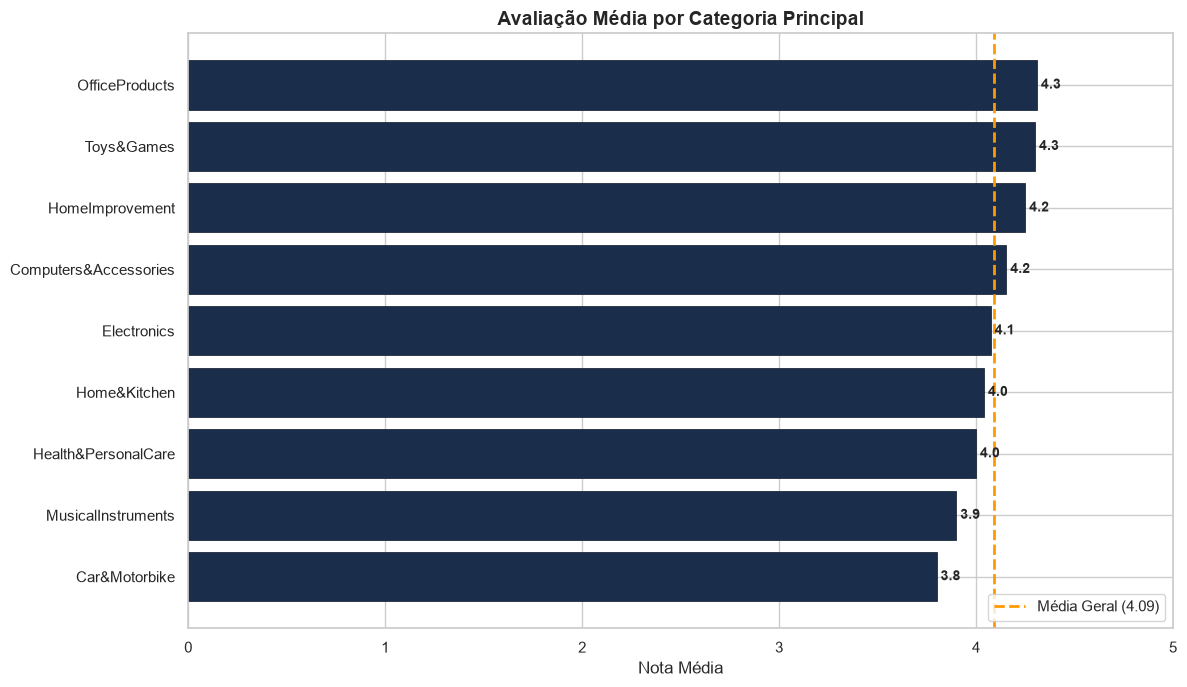

In [237]:
# --- GRÁFICO 1: Avaliação Média por Categoria ---

fig, ax = plt.subplots(figsize=(12, 7))

nota_por_cat = df_produtos.groupby('categoria_principal')['rating'].mean().sort_values(ascending=True)

barras = ax.barh(nota_por_cat.index, nota_por_cat.values,
                  color=AZUL_2, edgecolor=AZUL_1, linewidth=0.5)

# Adicionar valores nas barras
for barra in barras:
    width = barra.get_width()
    ax.text(width + 0.02, barra.get_y() + barra.get_height()/2,
            f'{width:.1f}', ha='left', va='center', fontsize=10, fontweight='bold')

# Linha de referência na média geral
ax.axvline(x=nota_media, color=LARANJA, linestyle='--', linewidth=2,
           label=f'Média Geral ({nota_media:.2f})')

ax.set_title('Avaliação Média por Categoria Principal', fontsize=14, fontweight='bold')
ax.set_xlabel('Nota Média')
ax.set_ylabel('')
ax.legend(loc='lower right')
ax.set_xlim(0, 5)

plt.tight_layout()
plt.savefig('pag1_avaliacao_categoria.png', dpi=150, bbox_inches='tight')
plt.show()

Engajamento total: 16,767,383


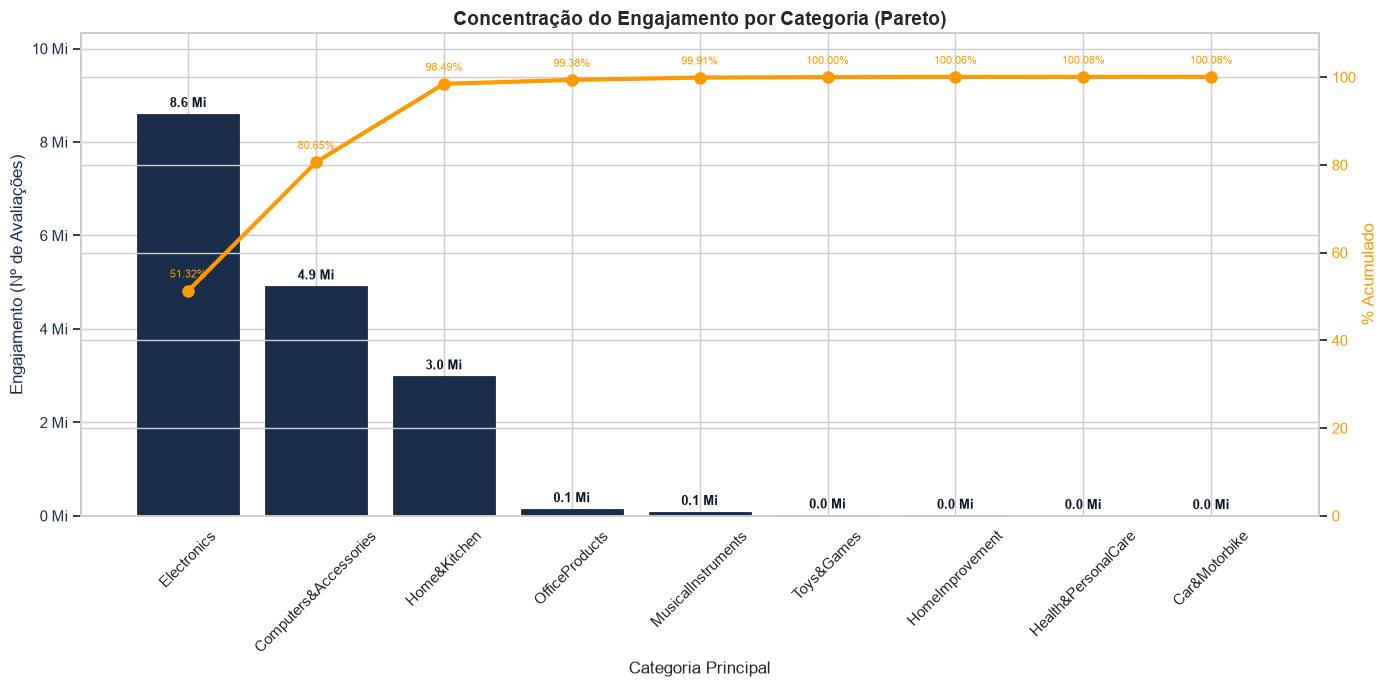

In [238]:
# --- GRÁFICO 2: Concentração do Engajamento por Categoria (Pareto) ---

fig, ax1 = plt.subplots(figsize=(14, 7))

# Engajamento por categoria SEM duplicatas
engajamento_cat = (df_produtos
                   .drop_duplicates(subset=['review_id', 'categoria_principal'])
                   .groupby('categoria_principal')['rating_count'].sum()
                   .sort_values(ascending=False))

# Total SEM duplicatas (16.767.393)
total_eng = df_produtos.drop_duplicates(subset='review_id')['rating_count'].sum()
print(f'Engajamento total: {total_eng:,.0f}')

# Barras de engajamento
barras = ax1.bar(engajamento_cat.index, engajamento_cat.values,
                 color=AZUL_2, edgecolor=AZUL_1, linewidth=0.5)

ax1.set_xlabel('Categoria Principal')
ax1.set_ylabel('Engajamento (Nº de Avaliações)', color=AZUL_2)
ax1.tick_params(axis='y', labelcolor=AZUL_2)
ax1.set_ylim(0, engajamento_cat.max() * 1.2)
ax1.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x/1e6:.0f} Mi'))

# Eixo secundário - % acumulado
ax2 = ax1.twinx()
acumulado = engajamento_cat.cumsum() / total_eng * 100  # divide pelo total sem duplicatas

ax2.plot(acumulado.index, acumulado.values,
         color=LARANJA, marker='o', linewidth=3, markersize=8)
ax2.set_ylabel('% Acumulado', color=LARANJA)
ax2.tick_params(axis='y', labelcolor=LARANJA)
ax2.set_ylim(0, 110)

# % acumulado escrito em cada ponto da linha
for x, y in zip(acumulado.index, acumulado.values):
    ax2.text(x, y + 3, f'{y:.2f}%', ha='center', fontsize=8, color=LARANJA)

# Valores nas barras
for barra in barras:
    height = barra.get_height()
    ax1.text(barra.get_x() + barra.get_width()/2., height + engajamento_cat.max() * 0.01,  # distância proporcional
             f'{height/1e6:.1f} Mi', ha='center', va='bottom',
             fontsize=9, fontweight='bold', color=AZUL_1)

ax1.set_title('Concentração do Engajamento por Categoria (Pareto)',
              fontsize=14, fontweight='bold')
ax1.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('pag1_pareto_engajamento.png', dpi=150, bbox_inches='tight')
plt.show()

In [239]:
# engajamento por categoria, sem duplicatas
eng_cat = (df_produtos
           .drop_duplicates(subset=['review_id', 'categoria_principal'])
           .groupby('categoria_principal')['rating_count'].sum()
           .sort_values(ascending=False))

# total sem duplicatas (16.767.393)
total = df_produtos.drop_duplicates(subset='review_id')['rating_count'].sum()

pct_acum = eng_cat.cumsum() / total * 100

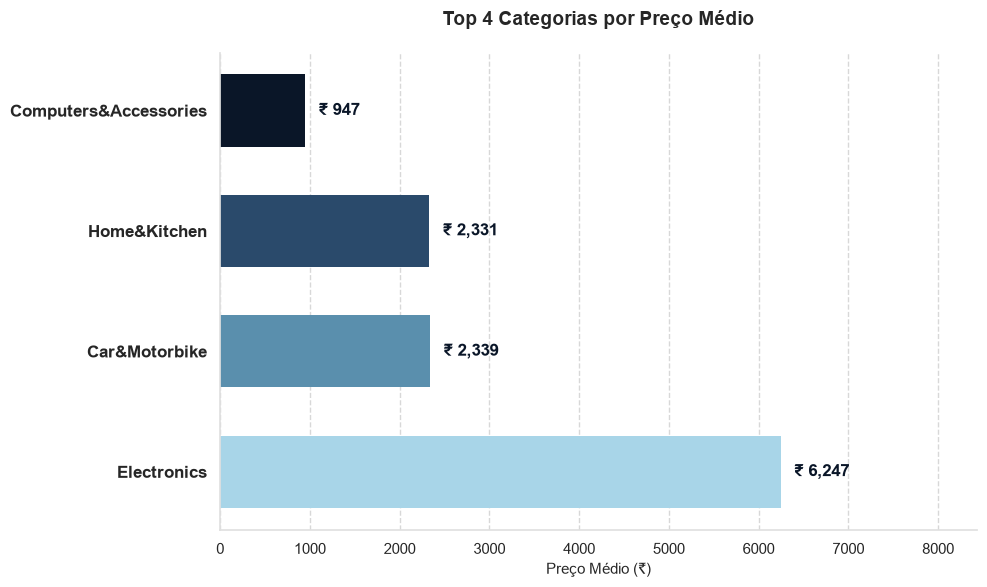

In [240]:
# ===== PREPARAÇÃO DOS DADOS (CORREÇÃO DE NAMEERROR) =====

# Extraímos as informações da variável 'preco_cat' gerada na etapa anterior
preco_cat_top4 = df_produtos.groupby('categoria_principal')['discounted_price'].mean().nlargest(4)
categorias = preco_cat_top4.index[::-1]
precos = preco_cat_top4.values[::-1]
cores = [AZUL_1, AZUL_3, AZUL_5, AZUL_7]

# ===== GRÁFICO =====
fig, ax = plt.subplots(figsize=(10, 6))
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

y_pos = np.arange(len(categorias))
barras = ax.barh(y_pos, precos, color=cores, edgecolor='none', height=0.6)

# CORREÇÃO PRINCIPAL: offset fixo + ha='left'
# Todos os textos ficam a exatamente 150 unidades à direita do fim da barra
offset = 150
for i, (barra, valor) in enumerate(zip(barras, precos)):
    ax.text(
        valor + offset,
        barra.get_y() + barra.get_height()/2,
        f'₹ {valor:,.0f}',
        ha='left',
        va='center',
        fontsize=12,
        fontweight='bold',
        color=AZUL_1
    )

# ===== FORMATAÇÃO =====
ax.set_yticks(y_pos)
ax.set_yticklabels(categorias, fontsize=12, fontweight='bold')
ax.invert_yaxis()

ax.set_title('Top 4 Categorias por Preço Médio', fontsize=14, fontweight='bold', pad=20)
ax.set_xlabel('Preço Médio (₹)', fontsize=11)

# Ajustar o xlim para dar espaço aos rótulos
ax.set_xlim(0, max(precos) * 1.35)

# Remover bordas superiores e direitas (visual mais limpo)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#E0E0E0')
ax.spines['bottom'].set_color('#E0E0E0')

# Grid horizontal suave
ax.xaxis.grid(True, linestyle='--', alpha=0.3, color='gray')
ax.yaxis.grid(False)

plt.tight_layout()
plt.savefig('pag1_top4_preco.png', dpi=150, bbox_inches='tight')
plt.show()

In [241]:
# --- TABELA: Variações do mesmo produto compartilham avaliações ---

# Mostrar produtos com mesmo rating_count (variações)
variacoes = df_produtos[df_produtos.duplicated(subset=['rating_count'], keep=False)]
variacoes = variacoes.sort_values('rating_count', ascending=False).head(10)

tabela_variacoes = variacoes[['product_name', 'categoria_principal',
                               'categoria_secundaria', 'actual_price',
                               'discounted_price', 'discount_percentage',
                               'rating', 'rating_count']].copy()

tabela_variacoes.columns = ['Nome do Produto', 'Categoria Principal',
                             'Subcategoria', 'Preço Original',
                             'Preço com Desconto', '% Desconto',
                             'Nota', 'Nº de Avaliações']

print("\n TABELA: Variações do mesmo produto")
print(tabela_variacoes.to_string(index=False))


 TABELA: Variações do mesmo produto
                                                                                                                                                                                    Nome do Produto   Categoria Principal                   Subcategoria  Preço Original  Preço com Desconto  % Desconto  Nota  Nº de Avaliações
                                                                                                                Amazon Basics High-Speed HDMI Cable, 6 Feet - Supports Ethernet, 3D, 4K video,Black           Electronics           HomeTheater,TV&Video           475.0               309.0        35.0   4.4            426973
                                                                                                                          AmazonBasics Flexible Premium HDMI Cable (Black, 4K@60Hz, 18Gbps), 3-Foot           Electronics           HomeTheater,TV&Video           700.0               219.0        69.0   4.4            426973


## *PÁGINA 2 - PRODUTOS E CATEGORIAS*


In [242]:
# --- Classificação nos 4 Quadrantes ---
media_engajamento = df_produtos['rating_count'].median()

def classificar_produto(row):
    if row['rating'] >= 4.0 and row['rating_count'] >= media_engajamento:
        return 'Estrela'
    elif row['rating'] < 4.0 and row['rating_count'] >= media_engajamento:
        return 'Problemático'
    elif row['rating'] >= 4.0 and row['rating_count'] < media_engajamento:
        return 'Joia Escondida'
    else:
        return 'A Repensar'

df_produtos['classificacao'] = df_produtos.apply(classificar_produto, axis=1)

# Contagem por quadrante
contagem_quad = df_produtos['classificacao'].value_counts()

print("Distribuição nos 4 Quadrantes:")
for classe, count in contagem_quad.items():
    pct = count / len(df_produtos) * 100
    print(f"   {classe}: {count} produtos ({pct:.1f}%)")

Distribuição nos 4 Quadrantes:
   Estrela: 558 produtos (41.7%)
   Joia Escondida: 438 produtos (32.8%)
   A Repensar: 229 produtos (17.1%)
   Problemático: 112 produtos (8.4%)


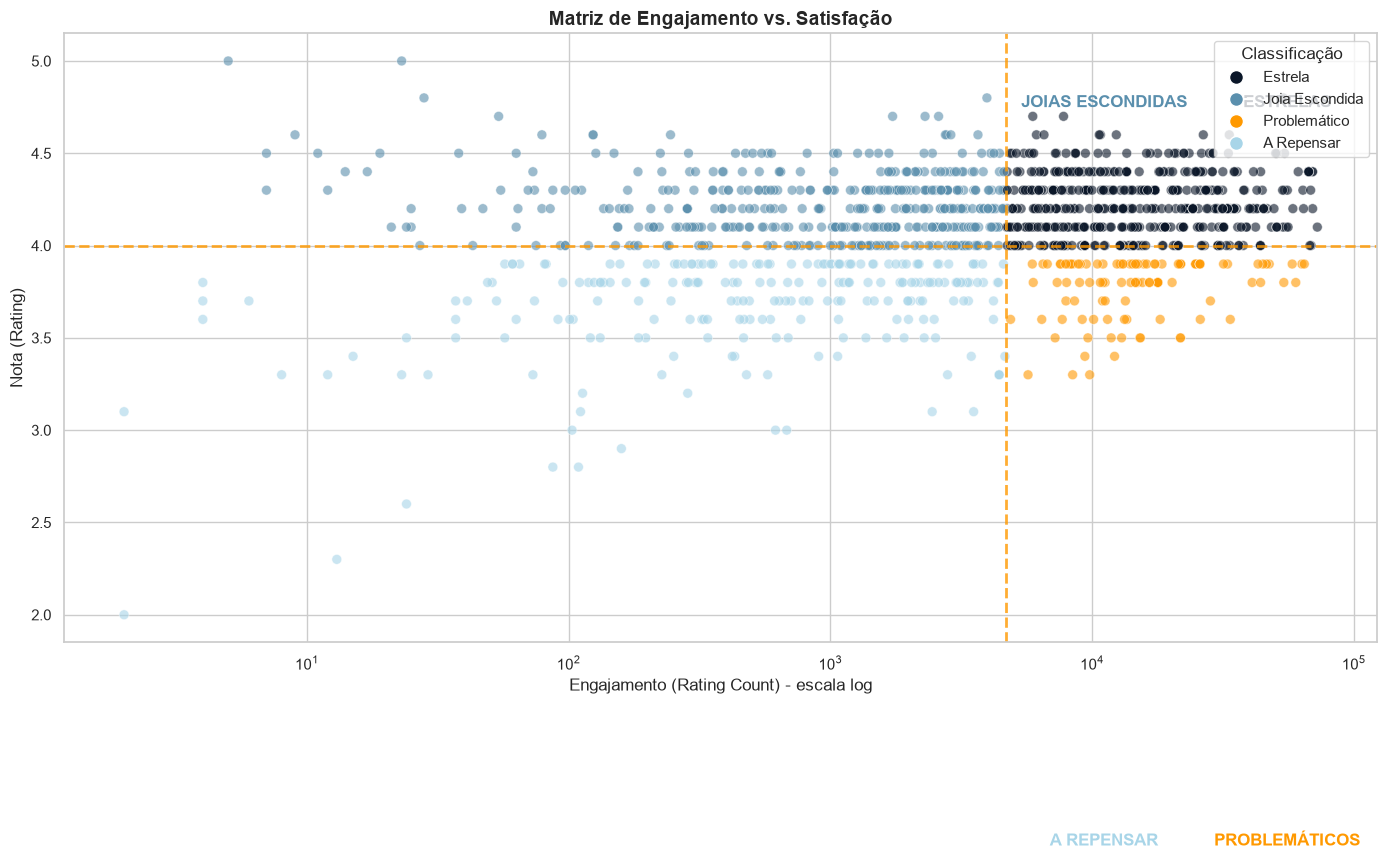

In [243]:
# --- GRÁFICO 1: Matriz de Engajamento × Satisfação (Scatter Plot) ---
fig, ax = plt.subplots(figsize=(14, 9))

# Cores por quadrante
cores_map = {
    'Estrela': AZUL_1,
    'Joia Escondida': AZUL_5,
    'Problemático': LARANJA,
    'A Repensar': AZUL_7
}

# Filtrar outliers para visualização melhor
df_plot = df_produtos[df_produtos['rating_count'] < df_produtos['rating_count'].quantile(0.95)].copy()

scatter = ax.scatter(df_plot['rating_count'], df_plot['rating'],
                      c=df_plot['classificacao'].map(cores_map),
                      alpha=0.6, s=50, edgecolors='white', linewidth=0.5)

# Linhas de corte
ax.axhline(y=4.0, color=LARANJA, linestyle='--', linewidth=2, alpha=0.8)
ax.axvline(x=media_engajamento, color=LARANJA, linestyle='--', linewidth=2, alpha=0.8)

# Labels dos quadrantes
max_x = df_plot['rating_count'].max()
max_y = df_plot['rating'].max()

ax.text(max_x * 0.75, max_y * 0.95, ' ESTRELAS',
        fontsize=12, fontweight='bold', color=AZUL_1, ha='center')
ax.text(max_x * 0.75, max_y * 0.15, ' PROBLEMÁTICOS',
        fontsize=12, fontweight='bold', color=LARANJA, ha='center')
ax.text(max_x * 0.15, max_y * 0.95, ' JOIAS ESCONDIDAS',
        fontsize=12, fontweight='bold', color=AZUL_5, ha='center')
ax.text(max_x * 0.15, max_y * 0.15, ' A REPENSAR',
        fontsize=12, fontweight='bold', color=AZUL_7, ha='center')

ax.set_title('Matriz de Engajamento vs. Satisfação', fontsize=14, fontweight='bold')
ax.set_xlabel('Engajamento (Rating Count) - escala log')
ax.set_ylabel('Nota (Rating)')
ax.set_xscale('log')

# Legenda
from matplotlib.lines import Line2D
legend_elements = [Line2D([0], [0], marker='o', color='w',
                          markerfacecolor=cor, markersize=10, label=classe)
                   for classe, cor in cores_map.items()]
ax.legend(handles=legend_elements, loc='upper right', title='Classificação')

plt.tight_layout()
plt.savefig('pag2_matriz_quadrantes.png', dpi=150, bbox_inches='tight')
plt.show()

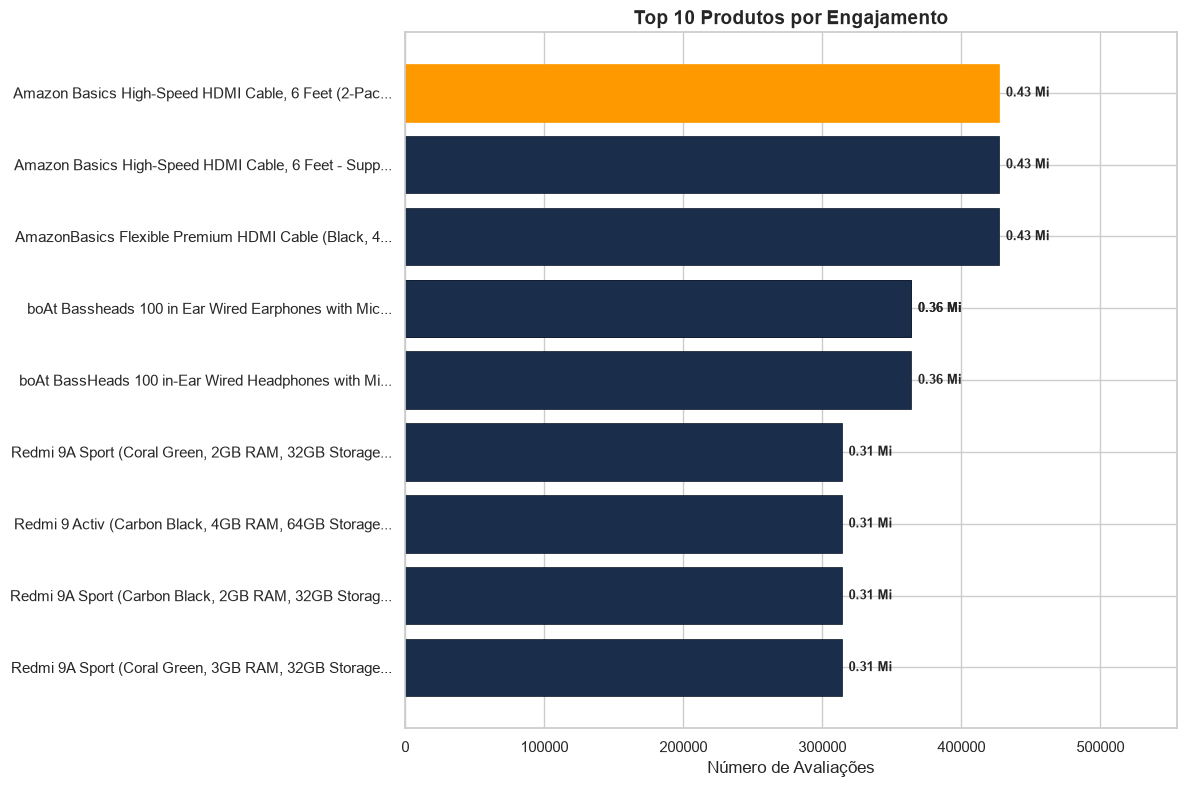

In [244]:
# --- GRÁFICO 2: Top 10 Produtos por Engajamento ---
fig, ax = plt.subplots(figsize=(12, 8))

top10 = df_produtos.nlargest(10, 'rating_count')[['product_name', 'rating_count']]
top10 = top10.sort_values('rating_count')

# Truncar nomes longos
top10['nome_curto'] = top10['product_name'].apply(lambda x: x[:50] + '...' if len(x) > 50 else x)

barras = ax.barh(top10['nome_curto'], top10['rating_count'],
                  color=AZUL_2, edgecolor=AZUL_1, linewidth=0.5)

# Destacar o #1 em laranja
barras[-1].set_color(LARANJA)

for barra in barras:
    width = barra.get_width()
    ax.text(width + 5000, barra.get_y() + barra.get_height()/2,
            f'{width/1e6:.2f} Mi', ha='left', va='center',
            fontsize=9, fontweight='bold')

ax.set_title('Top 10 Produtos por Engajamento', fontsize=14, fontweight='bold')
ax.set_xlabel('Número de Avaliações')
ax.set_xlim(0, top10['rating_count'].max() * 1.3)

plt.tight_layout()
plt.savefig('pag2_top10_engajamento.png', dpi=150, bbox_inches='tight')
plt.show()

In [245]:
# --- TABELA: Resumo por Categoria ---
resumo_cat = df_produtos.groupby('categoria_principal').agg({
    'product_id': 'count',
    'rating': 'mean',
    'discounted_price': 'mean'
}).rename(columns={
    'product_id': 'Total de Produtos',
    'rating': 'Nota Média',
    'discounted_price': 'Preço Médio'
})

# Engajamento por categoria SEM duplicatas
resumo_cat['Engajamento'] = (df_produtos
                             .drop_duplicates(subset=['review_id', 'categoria_principal'])
                             .groupby('categoria_principal')['rating_count'].sum())

# Ordena pelo engajamento, antes de formatar
resumo_cat = resumo_cat.sort_values('Engajamento', ascending=False)

# Colunas na mesma ordem do dashboard
resumo_cat = resumo_cat[['Total de Produtos', 'Nota Média', 'Engajamento', 'Preço Médio']]

resumo_cat['Nota Média'] = resumo_cat['Nota Média'].round(2)
resumo_cat['Engajamento'] = resumo_cat['Engajamento'].apply(lambda x: f"{x:,.0f}".replace(',', '.'))
resumo_cat['Preço Médio'] = resumo_cat['Preço Médio'].apply(lambda x: f"₹ {x:,.2f}")

print("\n TABELA: Resumo por Categoria")
print(resumo_cat.to_string())

# Total
total_eng = df_produtos.drop_duplicates(subset='review_id')['rating_count'].sum()  # total sem duplicatas

total_row = pd.DataFrame({
    'Total de Produtos': [len(df_produtos)],
    'Nota Média': [f"{df_produtos['rating'].mean():.2f}"],
    'Engajamento': [f"{total_eng:,.0f}".replace(',', '.')],
    'Preço Médio': [f"₹ {df_produtos['discounted_price'].mean():,.2f}"]
}, index=['Total'])

print("\n" + total_row.to_string())


 TABELA: Resumo por Categoria
                       Total de Produtos  Nota Média Engajamento Preço Médio
categoria_principal                                                         
Electronics                          476        4.07   8.605.502  ₹ 6,246.75
Computers&Accessories                375        4.15   4.917.225    ₹ 947.49
Home&Kitchen                         448        4.04   2.991.069  ₹ 2,330.62
OfficeProducts                        31        4.31     149.675    ₹ 301.58
MusicalInstruments                     2        3.90      88.882    ₹ 638.00
Toys&Games                             1        4.30      15.867    ₹ 150.00
HomeImprovement                        2        4.25       8.566    ₹ 337.00
Health&PersonalCare                    1        4.00       3.663    ₹ 899.00
Car&Motorbike                          1        3.80       1.118  ₹ 2,339.00

       Total de Produtos Nota Média Engajamento Preço Médio
Total               1337       4.09  16.767.383  ₹ 3,281.65


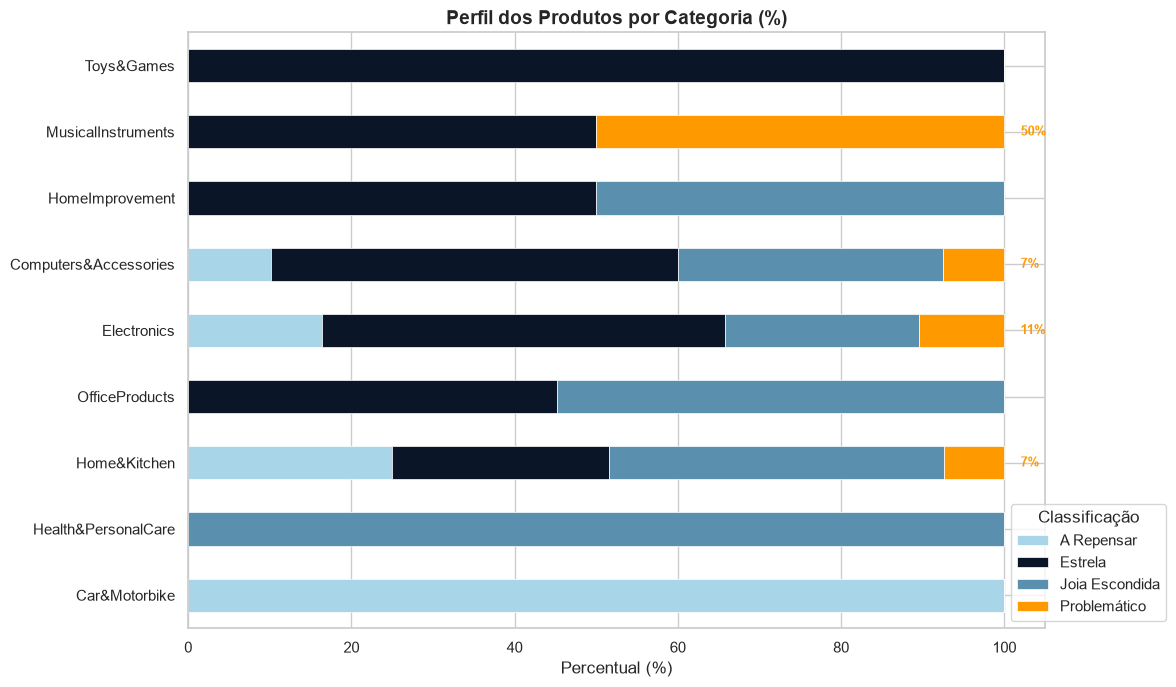

In [246]:
# --- GRÁFICO 3: Perfil dos produtos por categoria ---
fig, ax = plt.subplots(figsize=(12, 7))

perfil = df_produtos.groupby(['categoria_principal', 'classificacao']).size().unstack(fill_value=0)
perfil_pct = perfil.div(perfil.sum(axis=1), axis=0) * 100

# Ajustado para usar os nomes exatos com emojis que estão no DataFrame
perfil_pct = perfil_pct.sort_values('Estrela', ascending=True)

cores_ordem = [AZUL_7, AZUL_1, AZUL_5, LARANJA]  # A Repensar, Estrela, Joia, Problemático
cols_ordem = ['A Repensar', 'Estrela', 'Joia Escondida', 'Problemático']

perfil_pct[cols_ordem].plot(kind='barh', stacked=True, ax=ax,
                              color=cores_ordem, edgecolor='white', linewidth=0.5)

ax.set_title('Perfil dos Produtos por Categoria (%)', fontsize=14, fontweight='bold')
ax.set_xlabel('Percentual (%)')
ax.set_ylabel('')
ax.legend(title='Classificação', loc='lower right', bbox_to_anchor=(1.15, 0))
ax.set_xlim(0, 105)

# Adicionar % de problemáticos
for i, (idx, row) in enumerate(perfil_pct.iterrows()):
    prob_pct = row.get('Problemático', 0)
    if prob_pct > 0:
        ax.text(102, i, f'{prob_pct:.0f}%', ha='left', va='center',
                fontsize=9, fontweight='bold', color=LARANJA)

plt.tight_layout()
plt.savefig('pag2_perfil_categoria.png', dpi=150, bbox_inches='tight')
plt.show()

## *PÁGINA 3 - PREÇOS E ESTRATÉGIA COMERCIAL*


In [247]:
# --- KPIs ---
preco_original_medio = df_produtos['actual_price'].mean()
preco_medio = df_produtos['discounted_price'].mean()
desconto_medio_pct = df_produtos['discount_percentage'].mean()
correlacao = df_produtos[['discount_percentage', 'rating']].corr().iloc[0, 1]

print(f"   KPIs da Página 3:")
print(f"   Preço Original Médio: ₹ {preco_original_medio:,.2f}")
print(f"   Preço Médio (com desconto): ₹ {preco_medio:,.2f}")
print(f"   Desconto Médio: {desconto_medio_pct:.2f}%")
print(f"   Correlação Desconto × Nota: {correlacao:.3f}")

   KPIs da Página 3:
   Preço Original Médio: ₹ 5,589.00
   Preço Médio (com desconto): ₹ 3,281.65
   Desconto Médio: 46.48%
   Correlação Desconto × Nota: -0.168


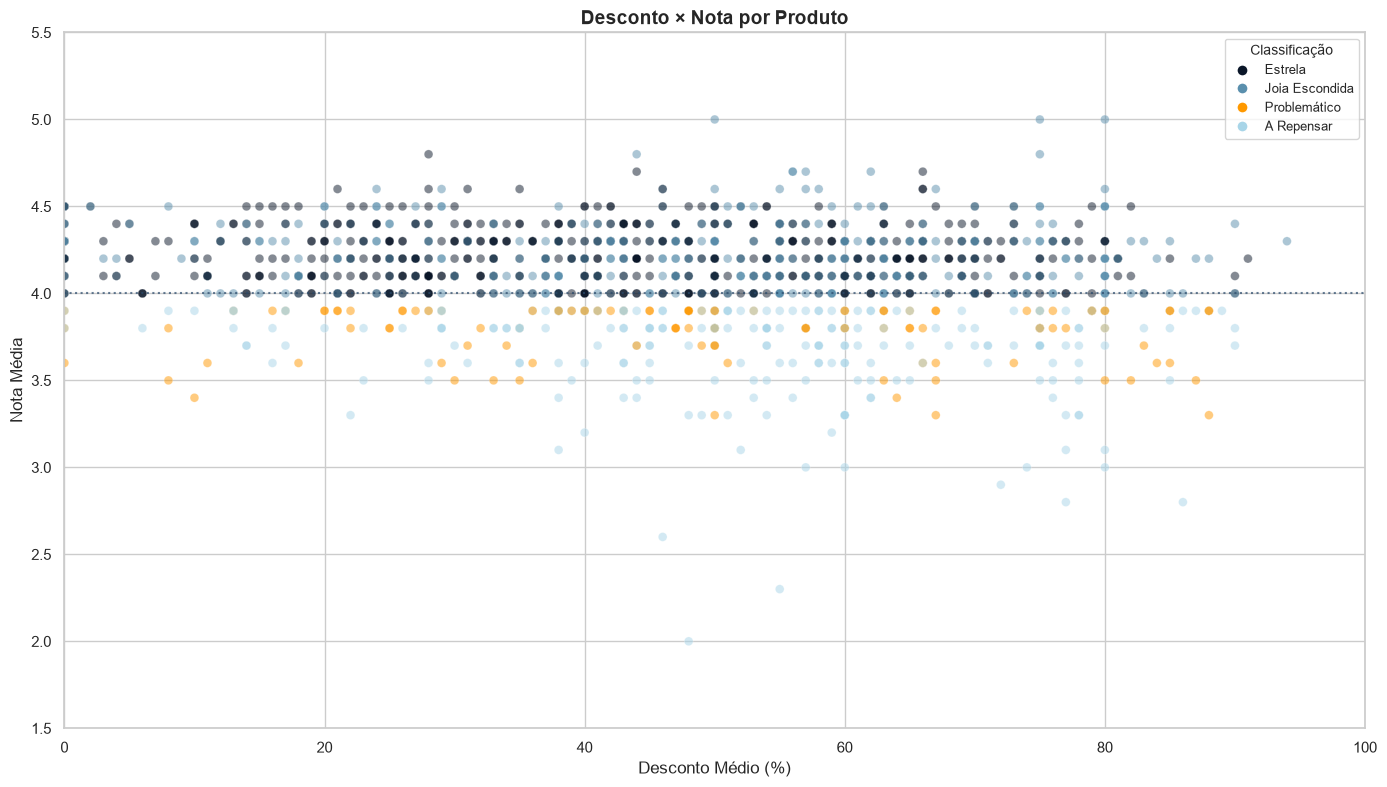

In [248]:
# --- GRÁFICO 1: Desconto × Nota por produto ---
fig, ax = plt.subplots(figsize=(14, 8))

df_plot3 = df_produtos[df_produtos['discount_percentage'] <= 100].copy()

scatter = ax.scatter(df_plot3['discount_percentage'], df_plot3['rating'],
                      c=df_plot3['classificacao'].map(cores_map),
                      alpha=0.5, s=40, edgecolors='white', linewidth=0.3)

# Linha de tendência
z = np.polyfit(df_plot3['discount_percentage'], df_plot3['rating'], 1)
p = np.poly1d(z)
x_trend = np.linspace(0, 100, 100)
ax.plot(x_trend, p(x_trend), color=LARANJA, linewidth=3, linestyle='--',
        label=f'Tendência (corr: {correlacao:.2f})')

# Linha de referência na nota 4.0
ax.axhline(y=4.0, color=AZUL_3, linestyle=':', linewidth=1.5, alpha=0.7)

ax.set_title('Desconto × Nota por Produto', fontsize=14, fontweight='bold')
ax.set_xlabel('Desconto Médio (%)')
ax.set_ylabel('Nota Média')
ax.set_xlim(0, 100)
ax.set_ylim(1.5, 5.5)
ax.legend()

# Legenda de cores
from matplotlib.lines import Line2D
legend_elements = [Line2D([0], [0], marker='o', color='w',
                          markerfacecolor=cor, markersize=8, label=classe)
                   for classe, cor in cores_map.items()]
ax.legend(handles=legend_elements, loc='upper right', title='Classificação',
          fontsize=9, title_fontsize=10)

plt.tight_layout()
plt.savefig('pag3_desconto_nota.png', dpi=150, bbox_inches='tight')
plt.show()

C:\Users\danie\AppData\Local\Temp\ipykernel_21956\3657061764.py:49: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


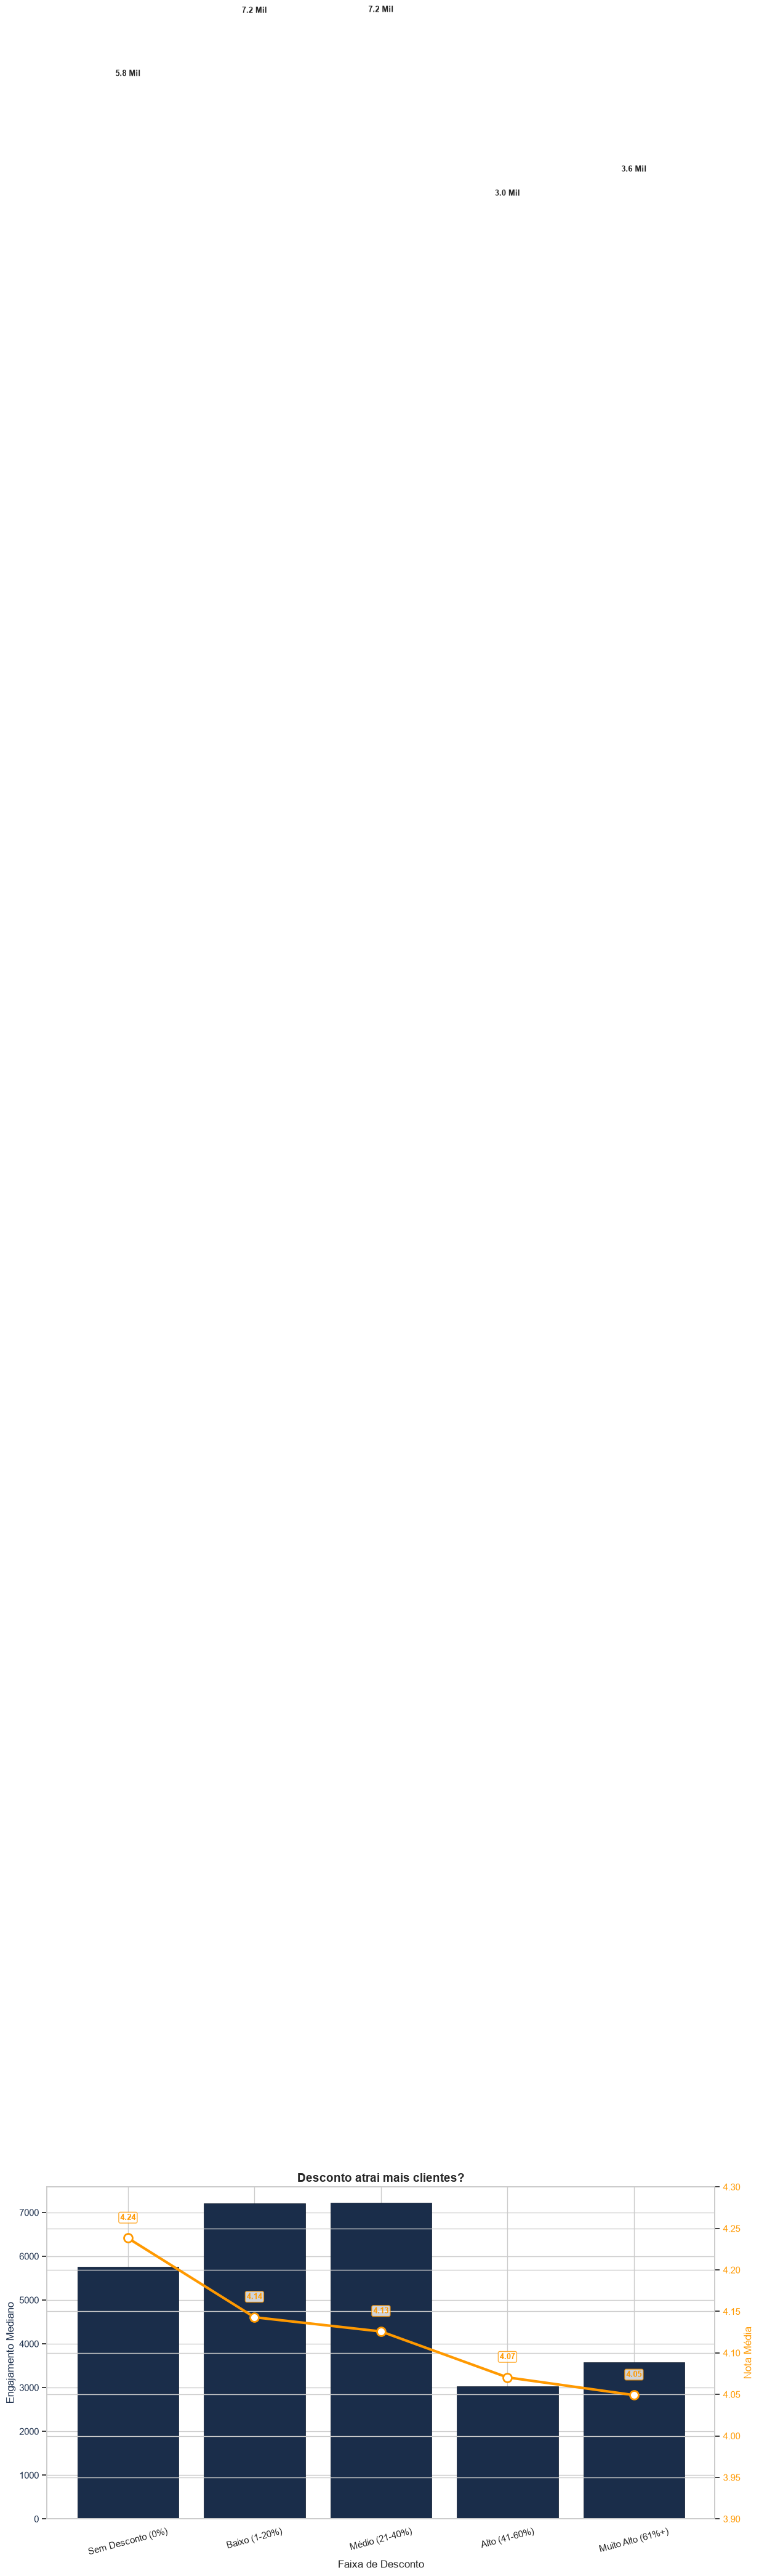

In [249]:
# --- GRÁFICO 2: Desconto atrai mais clientes? ---
fig, ax1 = plt.subplots(figsize=(14, 7))

# Criar faixas de desconto
faixas = ['Sem Desconto (0%)', 'Baixo (1-20%)', 'Médio (21-40%)',
          'Alto (41-60%)', 'Muito Alto (61%+)']
bins = [-1, 0, 20, 40, 60, 101]
df_produtos['faixa_desc'] = pd.cut(df_produtos['discount_percentage'],
                                     bins=bins, labels=faixas)

# Engajamento mediano por faixa
eng_mediano = df_produtos.groupby('faixa_desc', observed=True)['rating_count'].median()
nota_media_faixa = df_produtos.groupby('faixa_desc', observed=True)['rating'].mean()

# Barras - engajamento
barras = ax1.bar(eng_mediano.index, eng_mediano.values,
                  color=AZUL_2, edgecolor=AZUL_1, linewidth=0.5)

ax1.set_xlabel('Faixa de Desconto')
ax1.set_ylabel('Engajamento Mediano', color=AZUL_2)
ax1.tick_params(axis='y', labelcolor=AZUL_2)

# Eixo secundário - nota
ax2 = ax1.twinx()
ax2.plot(nota_media_faixa.index, nota_media_faixa.values,
         color=LARANJA, marker='o', linewidth=3, markersize=10,
         markerfacecolor='white', markeredgewidth=2, markeredgecolor=LARANJA)
ax2.set_ylabel('Nota Média', color=LARANJA)
ax2.tick_params(axis='y', labelcolor=LARANJA)
ax2.set_ylim(3.9, 4.3)

# Valores nas barras
for barra in barras:
    height = barra.get_height()
    ax1.text(barra.get_x() + barra.get_width()/2., height + 50000,
             f'{height/1000:.1f} Mil', ha='center', va='bottom',
             fontsize=9, fontweight='bold')

# Valores na linha
for i, (idx, val) in enumerate(nota_media_faixa.items()):
    ax2.text(i, val + 0.02, f'{val:.2f}', ha='center', va='bottom',
             fontsize=9, fontweight='bold', color=LARANJA,
             bbox=dict(boxstyle='round,pad=0.2', facecolor='white',
                       edgecolor=LARANJA, alpha=0.8))

ax1.set_title('Desconto atrai mais clientes?', fontsize=14, fontweight='bold')
ax1.tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.savefig('pag3_desconto_engajamento.png', dpi=150, bbox_inches='tight')
plt.show()

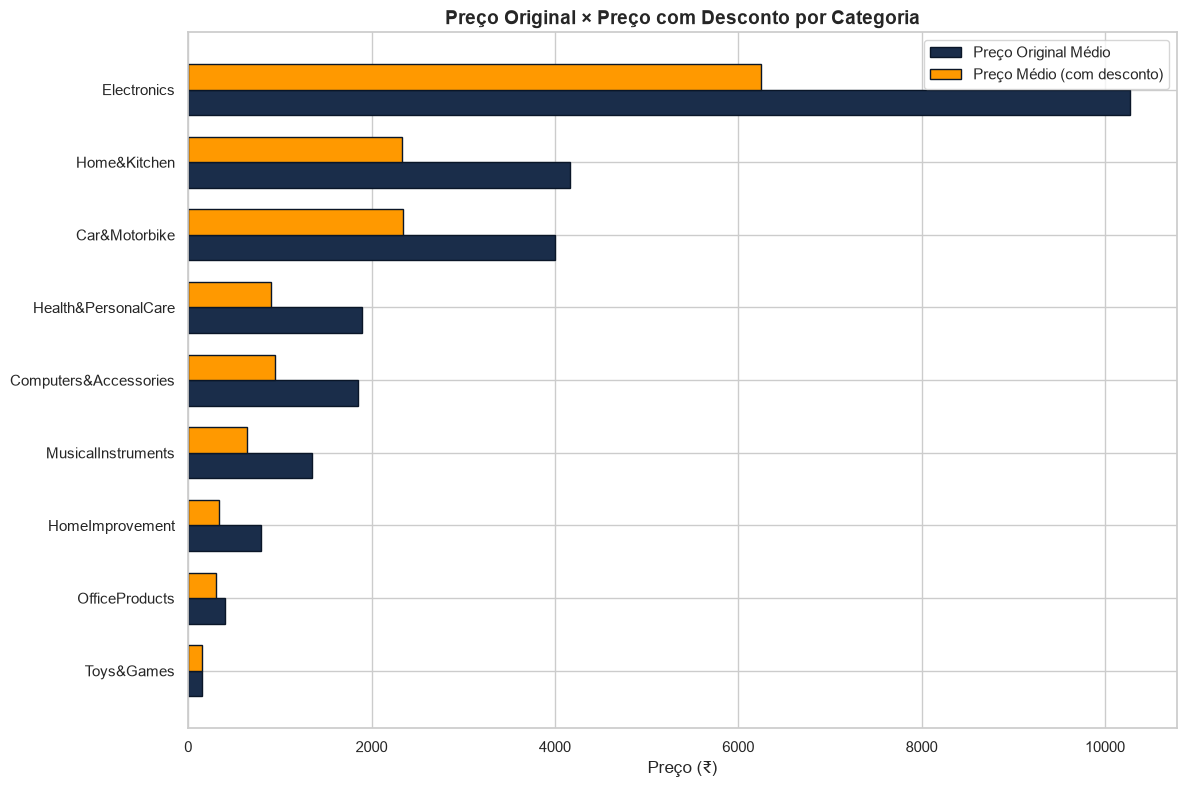

In [250]:
# --- GRÁFICO 3: Preço original × preço com desconto por categoria ---
fig, ax = plt.subplots(figsize=(12, 8))

preco_cat = df_produtos.groupby('categoria_principal').agg({
    'actual_price': 'mean',
    'discounted_price': 'mean'
}).sort_values('actual_price', ascending=True)

y_pos = np.arange(len(preco_cat))
bar_width = 0.35

barras1 = ax.barh(y_pos - bar_width/2, preco_cat['actual_price'],
                   bar_width, label='Preço Original Médio',
                   color=AZUL_2, edgecolor=AZUL_1)
barras2 = ax.barh(y_pos + bar_width/2, preco_cat['discounted_price'],
                   bar_width, label='Preço Médio (com desconto)',
                   color=LARANJA, edgecolor=AZUL_1)

ax.set_yticks(y_pos)
ax.set_yticklabels(preco_cat.index)
ax.set_xlabel('Preço (₹)')
ax.set_title('Preço Original × Preço com Desconto por Categoria',
             fontsize=14, fontweight='bold')
ax.legend()

plt.tight_layout()
plt.savefig('pag3_preco_categoria.png', dpi=150, bbox_inches='tight')
plt.show()

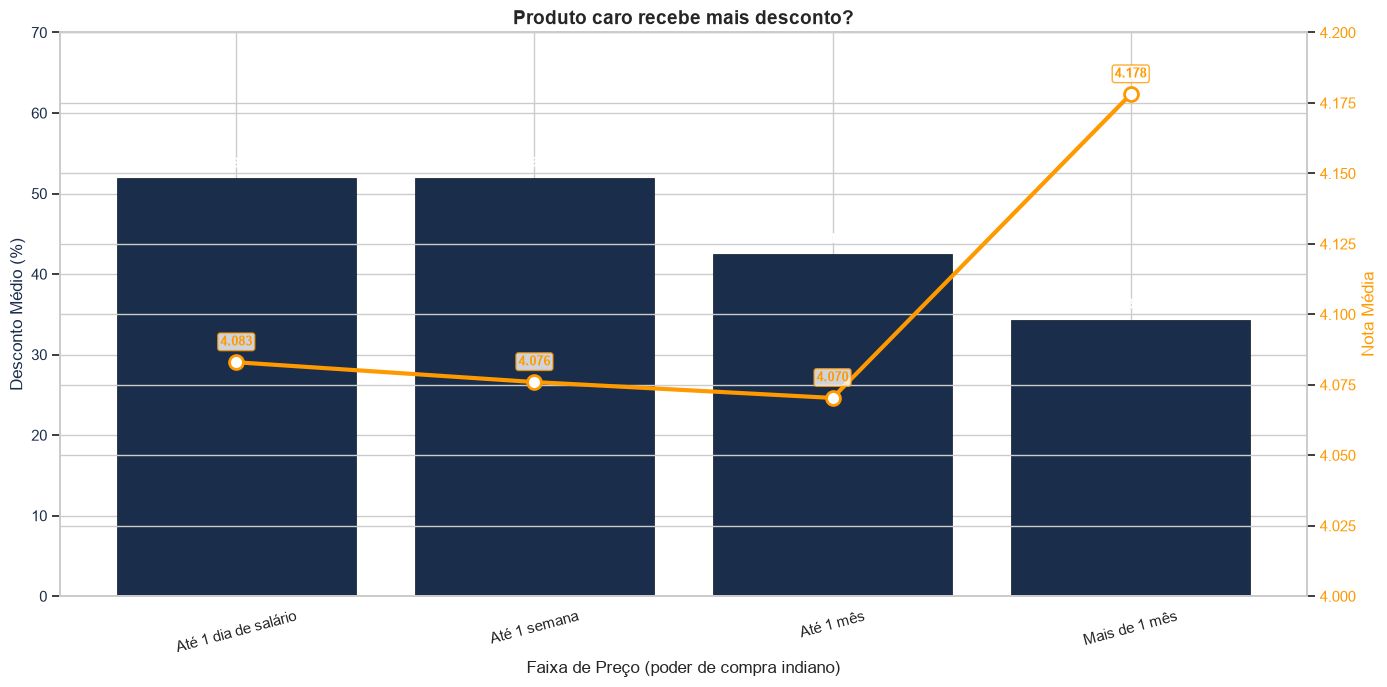

In [251]:
# --- GRÁFICO 4: Produto caro recebe mais desconto? ---
fig, ax1 = plt.subplots(figsize=(14, 7))

# Faixas de preço em dias de salário (₹178/dia)
faixas_preco = ['Até 1 dia de salário', 'Até 1 semana', 'Até 1 mês', 'Mais de 1 mês']
bins_preco = [0, 178, 1068, 4628, np.inf]
df_produtos['faixa_preco_sal'] = pd.cut(df_produtos['discounted_price'],
                                          bins=bins_preco, labels=faixas_preco)

desc_por_faixa = df_produtos.groupby('faixa_preco_sal', observed=True)['discount_percentage'].mean()
nota_por_faixa = df_produtos.groupby('faixa_preco_sal', observed=True)['rating'].mean()

# Barras - desconto
barras = ax1.bar(desc_por_faixa.index, desc_por_faixa.values,
                  color=AZUL_2, edgecolor=AZUL_1, linewidth=0.5)

ax1.set_xlabel('Faixa de Preço (poder de compra indiano)')
ax1.set_ylabel('Desconto Médio (%)', color=AZUL_2)
ax1.tick_params(axis='y', labelcolor=AZUL_2)
ax1.set_ylim(0, 70)

# Eixo secundário - nota
ax2 = ax1.twinx()
ax2.plot(nota_por_faixa.index, nota_por_faixa.values,
         color=LARANJA, marker='o', linewidth=3, markersize=10,
         markerfacecolor='white', markeredgewidth=2, markeredgecolor=LARANJA)
ax2.set_ylabel('Nota Média', color=LARANJA)
ax2.tick_params(axis='y', labelcolor=LARANJA)
ax2.set_ylim(4.0, 4.2)

# Valores
for i, (idx, val) in enumerate(desc_por_faixa.items()):
    ax1.text(i, val + 1, f'{val:.2f}%', ha='center', va='bottom',
             fontsize=10, fontweight='bold', color='white')

for i, (idx, val) in enumerate(nota_por_faixa.items()):
    ax2.text(i, val + 0.005, f'{val:.3f}', ha='center', va='bottom',
             fontsize=9, fontweight='bold', color=LARANJA,
             bbox=dict(boxstyle='round,pad=0.2', facecolor='white',
                       edgecolor=LARANJA, alpha=0.8))

ax1.set_title('Produto caro recebe mais desconto?', fontsize=14, fontweight='bold')
ax1.tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.savefig('pag3_produto_caro_desconto.png', dpi=150, bbox_inches='tight')
plt.show()

## *PÁGINA 4 - CUSTOMER INSIGHTS*



In [252]:
AZUL_CLARO = '#7EC8E3'
CATS = ['Computers&Accessories', 'Electronics', 'Home&Kitchen', 'OfficeProducts']

# categoria, nota e nome de cada produto
info = (df_produtos[['product_id', 'product_name', 'categoria_principal', 'rating']]
        .drop_duplicates(subset='product_id'))
base = df.merge(info, on='product_id', how='left')

# grupos de nota: bem (>= 4,3) e mal (<= 3,9) avaliados
base['grupo'] = np.select(
    [base['rating'] >= 4.3, base['rating'] <= 3.9],
    ['Bem avaliado', 'Mal avaliado'], default='Intermediário')

# quais temas cada produto cita
linhas = []
for _, r in base.iterrows():
    for tema, (tipo, palavras) in temas.items():
        if any(p in r['texto'] for p in palavras):
            linhas.append({'product_id': r['product_id'], 'tema': tema, 'tipo': tipo})

temas_df = pd.DataFrame(linhas).merge(
    base[['product_id', 'categoria_principal', 'grupo']], on='product_id')

In [253]:
pct_sent = base['sentimento'].value_counts(normalize=True) * 100
indice = base['pct_frases_negativas'].mean() * 100

print(f"% Produtos Positivos: {pct_sent['Positivo']:.2f}%")
print(f"% Produtos Mistos:    {pct_sent['Misto']:.2f}%")
print(f"% Produtos Negativos: {pct_sent['Negativo']:.2f}%")
print(f"Índice de Reclamação: {indice:.2f}%")

% Produtos Positivos: 93.25%
% Produtos Mistos:    3.04%
% Produtos Negativos: 3.71%
Índice de Reclamação: 12.34%


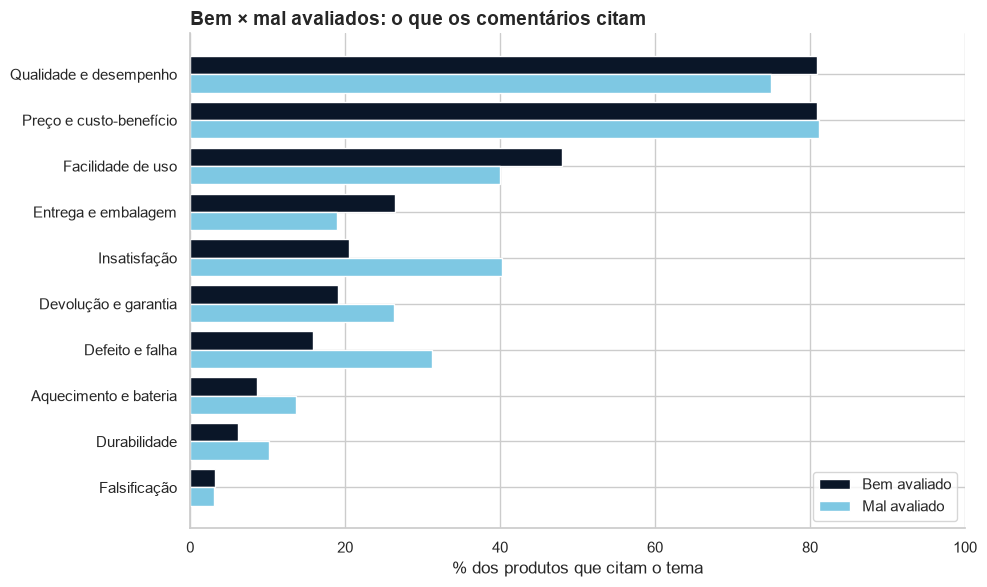

In [254]:
n_grupo = base['grupo'].value_counts()

pct_grupo = (temas_df[temas_df['grupo'] != 'Intermediário']
             .groupby(['tema', 'grupo'])['product_id'].nunique()
             .div(n_grupo, level='grupo')
             .unstack(fill_value=0) * 100)
pct_grupo = pct_grupo.sort_values('Bem avaliado')

fig, ax = plt.subplots(figsize=(10, 6))
y = np.arange(len(pct_grupo))
ax.barh(y + 0.2, pct_grupo['Bem avaliado'], height=0.4, color=AZUL_1, label='Bem avaliado')
ax.barh(y - 0.2, pct_grupo['Mal avaliado'], height=0.4, color=AZUL_CLARO, label='Mal avaliado')
ax.set_yticks(y, pct_grupo.index)
ax.set_xlim(0, 100)
ax.set_xlabel('% dos produtos que citam o tema')
ax.set_title('Bem × mal avaliados: o que os comentários citam',
             fontsize=14, fontweight='bold', loc='left')
ax.legend(loc='lower right')
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('pag4_bem_mal_avaliados.png', dpi=150, bbox_inches='tight')
plt.show()

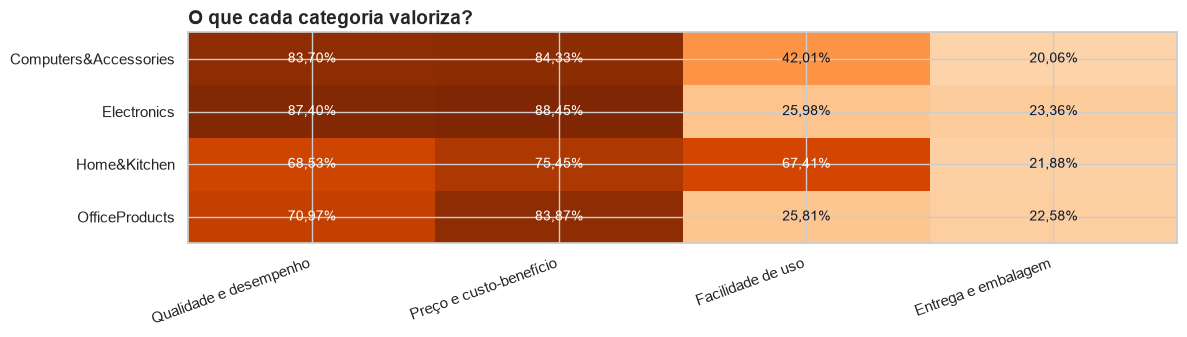

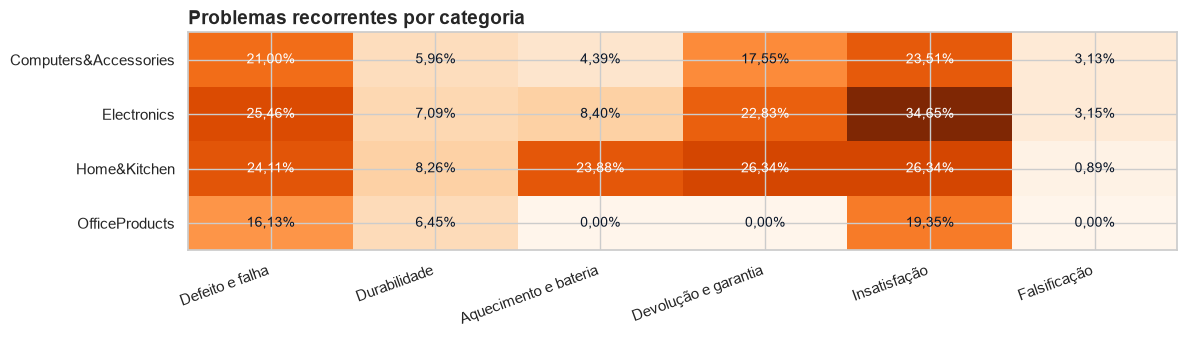

In [255]:
n_cat = base.groupby('categoria_principal')['product_id'].nunique()

pct_cat = (temas_df.groupby(['categoria_principal', 'tema'])['product_id'].nunique()
           .div(n_cat, level='categoria_principal')
           .unstack(fill_value=0) * 100).reindex(CATS)

def heatmap(tabela, titulo, arquivo):
    fig, ax = plt.subplots(figsize=(12, 3.5))
    vmax = tabela.values.max()
    ax.imshow(tabela.values, cmap='Oranges', aspect='auto', vmin=0, vmax=vmax)
    ax.set_xticks(range(tabela.shape[1]), tabela.columns, rotation=20, ha='right')
    ax.set_yticks(range(tabela.shape[0]), tabela.index)
    for i in range(tabela.shape[0]):
        for j in range(tabela.shape[1]):
            v = tabela.iat[i, j]
            ax.text(j, i, f'{v:.2f}%'.replace('.', ','), ha='center', va='center',
                    color='white' if v > 0.6 * vmax else AZUL_1, fontsize=10)
    ax.set_title(titulo, fontsize=14, fontweight='bold', loc='left')
    plt.tight_layout()
    plt.savefig(arquivo, dpi=150, bbox_inches='tight')
    plt.show()

valoriza = [t for t, (tipo, _) in temas.items() if tipo == 'Valoriza']
problemas = [t for t, (tipo, _) in temas.items() if tipo == 'Problema']

heatmap(pct_cat.reindex(columns=valoriza, fill_value=0),
        'O que cada categoria valoriza?', 'pag4_valoriza.png')
heatmap(pct_cat.reindex(columns=problemas, fill_value=0),
        'Problemas recorrentes por categoria', 'pag4_problemas.png')

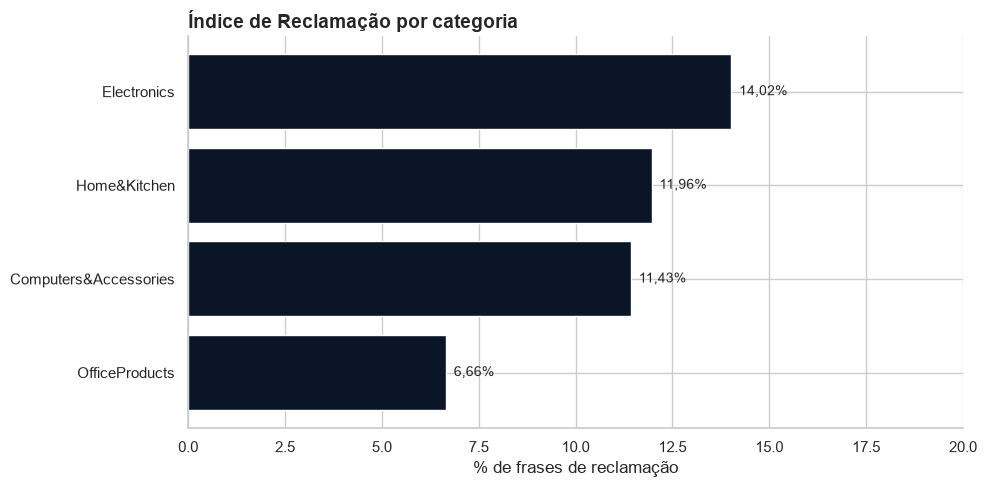

In [256]:
indice_cat = (base[base['categoria_principal'].isin(CATS)]
              .groupby('categoria_principal')['pct_frases_negativas'].mean() * 100
              ).sort_values()

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(indice_cat.index, indice_cat.values, color=AZUL_1)
for i, v in enumerate(indice_cat.values):
    ax.text(v + 0.2, i, f'{v:.2f}%'.replace('.', ','), va='center', fontsize=10)
ax.set_xlim(0, 20)
ax.set_xlabel('% de frases de reclamação')
ax.set_title('Índice de Reclamação por categoria', fontsize=14, fontweight='bold', loc='left')
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('pag4_indice_reclamacao.png', dpi=150, bbox_inches='tight')
plt.show()

In [257]:
negativos = (base.sort_values('score')
             [['product_name', 'review_title', 'categoria_principal',
               'rating', 'sentimento', 'score']]
             .head(10).copy())
negativos['product_name'] = negativos['product_name'].str[:40]
negativos['review_title'] = negativos['review_title'].str[:60]

print(' Reviews mais negativos')
print(negativos.to_string(index=False))

 Reviews mais negativos
                            product_name                                                 review_title categoria_principal  rating sentimento   score
                Realme Smart TV Stick 4K Great Product,Very good and working very nice,Horrible user          Electronics     4.5   Negativo -0.9752
Aquaguard Aura RO+UV+UF+Taste Adjuster(M Usable,Good,Awesome,Satisfied,Purifier,Beware to buy it from        Home&Kitchen     4.0   Negativo -0.9743
Morphy Richards OFR Room Heater, 09 Fin  Good product and recommend too,Good Purchase,It cannot warm         Home&Kitchen     4.0   Negativo -0.9713
OnePlus 108 cm (43 inches) Y Series 4K U Decent product. Value for money.,Value for money,Improvement         Electronics     4.2   Negativo -0.9658
Bulfyss Plastic Sticky Lint Roller Hair  This is a good product,Not upto the expectation,Not recommen        Home&Kitchen     3.5   Negativo -0.9581
Havells Ventil Air DX 200mm Exhaust Fan  Nice,Perfect. Reliable. Standard size. Go

## *PÁGINA 5 - RECOMENDAÇÕES*

In [258]:
# --- TABELA 1: Top 10 Problemáticos ---
problematicos = df_produtos[df_produtos['classificacao'] == 'Problemático'].copy()
top10_prob = problematicos.nlargest(10, 'rating_count')[
    ['product_name', 'categoria_principal', 'categoria_secundaria',
     'rating', 'rating_count']
].copy()

top10_prob.columns = ['Produto', 'Categoria', 'Subcategoria', 'Nota', 'Nº de Avaliações']
top10_prob['Nota'] = top10_prob['Nota'].round(2)
top10_prob['Nº de Avaliações'] = top10_prob['Nº de Avaliações'].apply(lambda x: f"{x:,.0f}")

print("PRIORIDADE DE QUALIDADE: Top 10 Problemáticos")
print(top10_prob.to_string(index=False))

PRIORIDADE DE QUALIDADE: Top 10 Problemáticos
                                                                                                                                                                                               Produto    Categoria                   Subcategoria  Nota Nº de Avaliações
                  boAt Airdopes 121v2 in-Ear True Wireless Earbuds with Upto 14 Hours Playback, 8MM Drivers, Battery Indicators, Lightweight Earbuds & Multifunction Controls (Active Black, with Mic)  Electronics Headphones,Earbuds&Accessories   3.8          180,998
        boAt Airdopes 141 Bluetooth Truly Wireless in Ear Earbuds with mic, 42H Playtime, Beast Mode(Low Latency Upto 80ms) for Gaming, ENx Tech, ASAP Charge, IWP, IPX4 Water Resistance (Bold Black)  Electronics Headphones,Earbuds&Accessories   3.9          136,954
            Pigeon by Stovekraft Amaze Plus Electric Kettle (14289) with Stainless Steel Body, 1.5 litre, used for boiling Water, making tea and coffee, ins

In [259]:
# --- TABELA 2: Top 10 Joias Escondidas ---
joias = df_produtos[df_produtos['classificacao'] == 'Joia Escondida'].copy()
top10_joias = joias.nlargest(10, 'rating')[
    ['product_name', 'categoria_principal', 'categoria_secundaria',
     'rating', 'rating_count']
].copy()

top10_joias.columns = ['Produto', 'Categoria', 'Subcategoria', 'Nota', 'Nº de Avaliações']
top10_joias['Nota'] = top10_joias['Nota'].round(2)
top10_joias['Nº de Avaliações'] = top10_joias['Nº de Avaliações'].apply(lambda x: f"{x:,.0f}")

print("\n OPORTUNIDADE DE VISIBILIDADE: Top 10 Joias Escondidas")
print(top10_joias.to_string(index=False))


 OPORTUNIDADE DE VISIBILIDADE: Top 10 Joias Escondidas
                                                                                                                                                                                                                                                                     Produto             Categoria               Subcategoria  Nota Nº de Avaliações
                                                                                                          Amazon Basics Wireless Mouse | 2.4 GHz Connection, 1600 DPI | Type - C Adapter | Upto 12 Months of Battery Life | Ambidextrous Design | Suitable for PC/Mac/Laptop Computers&Accessories    Accessories&Peripherals   5.0               23
                                                                               REDTECH USB-C to Lightning Cable 3.3FT, [Apple MFi Certified] Lightning to Type C Fast Charging Cord Compatible with iPhone 14/13/13 pro/Max/12/11/X/XS/XR/8, Supports Power Delivery -

C:\Users\danie\AppData\Local\Temp\ipykernel_21956\571473843.py:83: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\danie\AppData\Local\Temp\ipykernel_21956\571473843.py:84: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) Arial.
  plt.savefig('pag5_recomendacoes.png', dpi=150, bbox_inches='tight')
c:\Users\danie\Desktop\Fiap\TechChallenge4\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


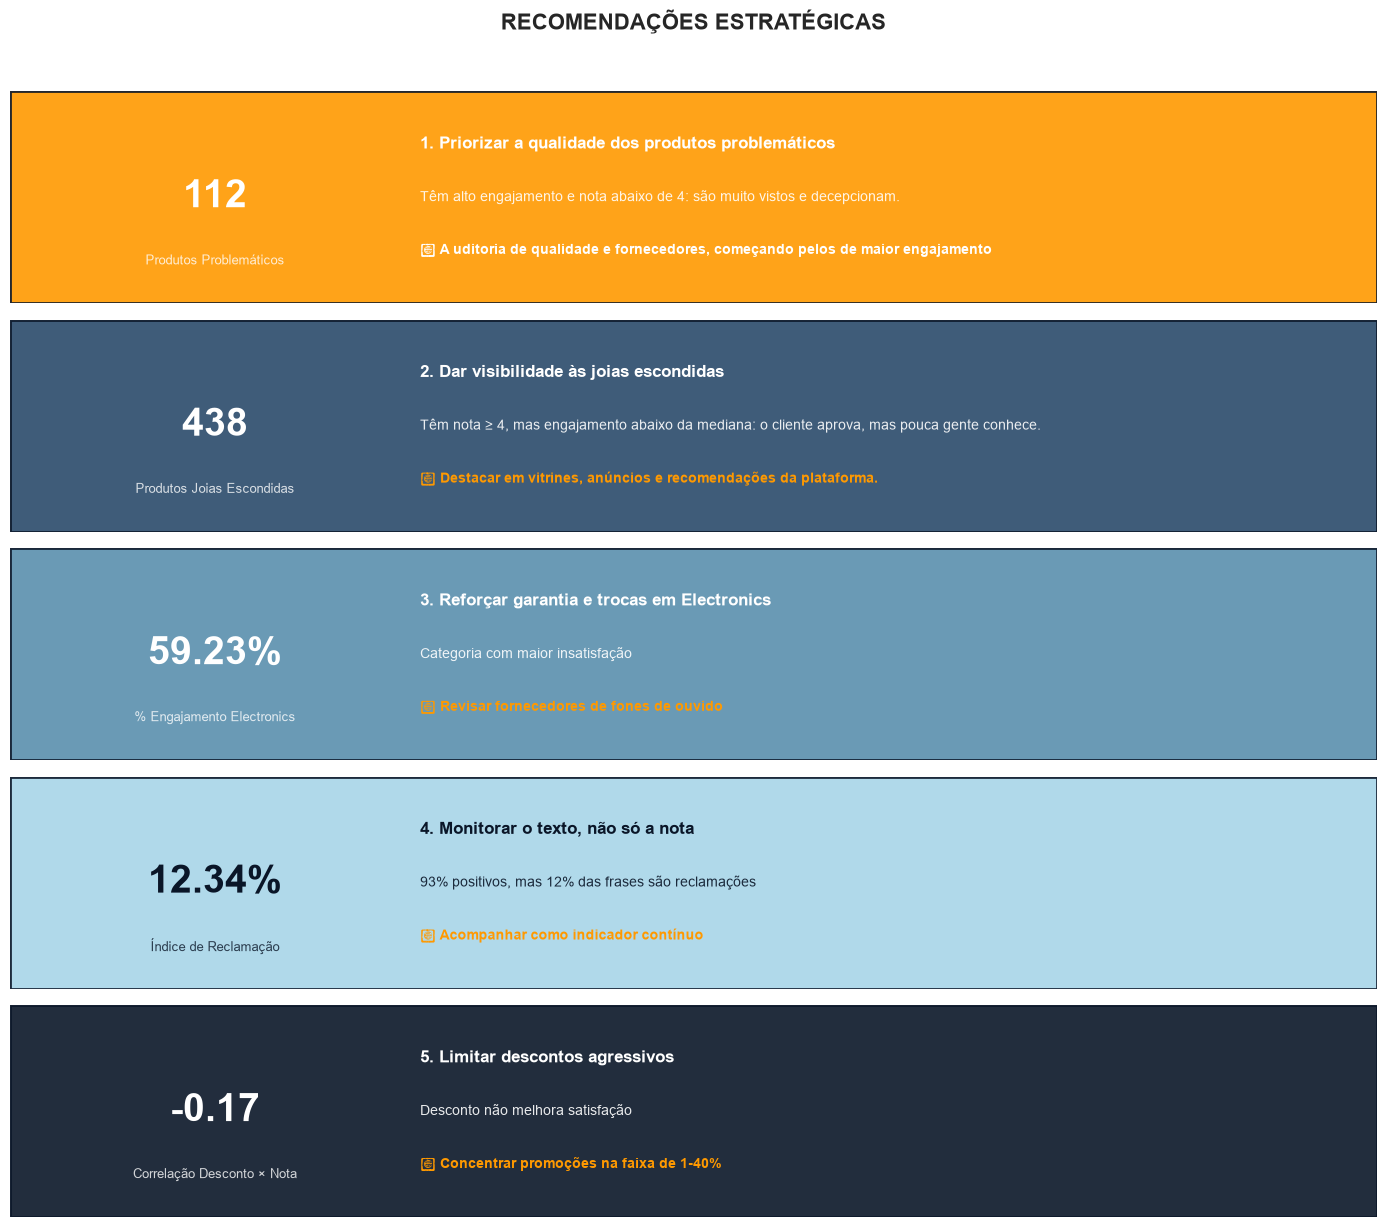

In [260]:
# --- GRÁFICO: Resumo das 5 Recomendações ---
fig, axes = plt.subplots(5, 1, figsize=(14, 12))

recomendacoes = [
    {
        'titulo': '1. Priorizar a qualidade dos produtos problemáticos',
        'valor': f'{len(problematicos)}',
        'subtitulo': 'Produtos Problemáticos',
        'descricao': 'Têm alto engajamento e nota abaixo de 4: são muito vistos e decepcionam.',
        'acao': 'A uditoria de qualidade e fornecedores, começando pelos de maior engajamento',
        'cor_fundo': LARANJA,
        'cor_texto': 'white'
    },
    {
        'titulo': '2. Dar visibilidade às joias escondidas',
        'valor': f'{len(joias)}',
        'subtitulo': 'Produtos Joias Escondidas',
        'descricao': 'Têm nota ≥ 4, mas engajamento abaixo da mediana: o cliente aprova, mas pouca gente conhece.',
        'acao': 'Destacar em vitrines, anúncios e recomendações da plataforma.',
        'cor_fundo': AZUL_3,
        'cor_texto': 'white'
    },
    {
        'titulo': '3. Reforçar garantia e trocas em Electronics',
        'valor': f"{df_produtos[df_produtos['categoria_principal']=='Electronics']['rating_count'].sum() / df_produtos['rating_count'].sum() * 100:.2f}%",
        'subtitulo': '% Engajamento Electronics',
        'descricao': 'Categoria com maior insatisfação',
        'acao': 'Revisar fornecedores de fones de ouvido',
        'cor_fundo': AZUL_5,
        'cor_texto': 'white'
    },
    {
        'titulo': '4. Monitorar o texto, não só a nota',
        'valor': f'{indice:.2f}%',
        'subtitulo': 'Índice de Reclamação',
        'descricao': '93% positivos, mas 12% das frases são reclamações',
        'acao': 'Acompanhar como indicador contínuo',
        'cor_fundo': AZUL_7,
        'cor_texto': AZUL_1
    },
    {
        'titulo': '5. Limitar descontos agressivos',
        'valor': f'{correlacao:.2f}',
        'subtitulo': 'Correlação Desconto × Nota',
        'descricao': 'Desconto não melhora satisfação',
        'acao': 'Concentrar promoções na faixa de 1-40%',
        'cor_fundo': AZUL_1,
        'cor_texto': 'white'
    }
]

for idx, (ax, rec) in enumerate(zip(axes, recomendacoes)):
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 1)
    ax.axis('off')

    # Caixa principal
    rect = plt.Rectangle((0, 0), 10, 1, facecolor=rec['cor_fundo'],
                          edgecolor=AZUL_1, linewidth=2, alpha=0.9)
    ax.add_patch(rect)

    # Valor grande
    ax.text(1.5, 0.5, rec['valor'], ha='center', va='center',
            fontsize=28, fontweight='bold', color=rec['cor_texto'])

    # Subtítulo
    ax.text(1.5, 0.2, rec['subtitulo'], ha='center', va='center',
            fontsize=9, color=rec['cor_texto'], alpha=0.8)

    # Título
    ax.text(3, 0.75, rec['titulo'], ha='left', va='center',
            fontsize=12, fontweight='bold', color=rec['cor_texto'])

    # Descrição
    ax.text(3, 0.5, rec['descricao'], ha='left', va='center',
            fontsize=10, color=rec['cor_texto'], alpha=0.9)

    # Ação
    ax.text(3, 0.25, f"🎯 {rec['acao']}", ha='left', va='center',
            fontsize=10, fontweight='bold', color=LARANJA if rec['cor_fundo'] != LARANJA else 'white')

plt.suptitle('RECOMENDAÇÕES ESTRATÉGICAS', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('pag5_recomendacoes.png', dpi=150, bbox_inches='tight')
plt.show()